# Stationary beamforming comparisons

This notebook separates posterior uncertainty, finite optimization and validation choices. It reads completed audit records from the original observations and independent validation/test simulation identifiers. This comparison audit preserves original raw records and estimator settings; it does not rewrite existing application notebooks or their result files. Every figure has visible plotting code and exports only to this audit directory.

In [1]:
from pathlib import Path
import os
import sys
ROOT = Path.cwd() if (Path.cwd() / 'lib').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
LOCAL_TEX = Path('/workspace/.local/tex')
if (LOCAL_TEX / 'usr/bin/dvipng').exists():
    os.environ['PATH'] = str(LOCAL_TEX / 'usr/bin') + os.pathsep + os.environ['PATH']
    os.environ.setdefault('TEXMFHOME', str(LOCAL_TEX / 'usr/share/texmf'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import t as student_t
from IPython import get_ipython
from IPython.display import Markdown, HTML, display
from lib.beamforming_comparison_summaries import load_existing_beamforming_comparisons
from lib.beamforming_mean_validation_audit import load_mean_validation_audit
from lib.beamforming_objective_audit import load_objective_audit

SCOPE = 'stationary'
# These controls identify already completed audits; changing them does not fit a model.
CONFIG = {'T': 200, 'dimensions': [32, 64, 128], 'common_beta': 1.0, 'primary_t': 200, 'test_simulations': 256, 'sigma2': 0.2, 'tau2': 1.0, 'validation_simulations': 64}
existing = load_existing_beamforming_comparisons(ROOT)[SCOPE]
mean_audit = load_mean_validation_audit(ROOT, scope=SCOPE)
optimization = load_objective_audit(ROOT, cohort=SCOPE)
assert existing['config']['T'] == CONFIG['T']
assert existing['config']['beta'] == CONFIG['common_beta']
if optimization['timing'] is None:
    raise RuntimeError('Complete the isolated timing audit before executing this notebook')
if SCOPE == 'stationary':
    from lib.beamforming_stationary_selection_audit import load_stationary_selection_audit
    selection = load_stationary_selection_audit(ROOT)
EDITABLE_OUTPUT = ROOT / 'results/beamforming_comparison_audit' / SCOPE / 'figures'
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
    get_ipython().run_line_magic('config', "InlineBackend.figure_format = 'png'")
    get_ipython().run_line_magic('config', "InlineBackend.print_figure_kwargs = {'bbox_inches': None}")
plt.rcParams.update({
    'text.usetex': True,
    'text.latex.preamble': r'\usepackage{amsmath}\usepackage{amssymb}',
    'font.family': 'serif', 'lines.linewidth': 1.8, 'lines.markersize': 5.,
    'savefig.bbox': None, 'figure.max_open_warning': 0,
})
print('Verified completed comparison, validation, objective and isolated-timing records:', SCOPE)


Verified completed comparison, validation, objective and isolated-timing records: stationary


## Loss and evaluation procedure

For $R_t=\sigma^2I_n+\tau^2P_{\mathcal X_t}$, $p_t^\star=(a^HR_t^{-1}a)^{-1}$ and a distortionless beamformer $w_t$, the reported loss is
\[
\ell_t=10\log_{10}\frac{w_t^HR_tw_t}{p_t^\star}.
\]
The posterior-mean MVDR rule minimizes posterior **expected linear output power**, $\mathbb E_q[w^H R_{\mathcal X}w]$, under the distortionless constraint. It does not generally minimize $\mathbb E_q[10\log_{10}(w^H R_{\mathcal X}w)]$. The primary benchmark below averages individual dB losses over a fixed generating cohort, which is a different risk. A reversed ranking therefore does not contradict the linear-power Bayes decision.

Evaluation uses this saved exact-covariance loss. Parameter selection uses independent measured output power on 64 validation simulations; true covariance and oracle power do not select a setting. Reported test confidence intervals are pointwise Student 95% intervals across 256 paired test simulations. They are not simultaneous confidence statements across algorithms and cases. Validation bands use the separate 64 validation simulations.

The posterior mean, mode and matched isotropic mean use the same posterior parameter in the controlled comparison. Their differences preserve memory and scale settings. Changing a separately selected memory, observation window or number of gradient steps is another comparison.

## Stationary data: exactly $T=200$ measurements at every dimension

The primary endpoint is $\ell_T$ at $T=200$, for $n=32,64,128$. The controlled mean/mode/isotropic comparison retains $\beta=1$. The first figure uses the original settings, including both GREAT references and the regularized sample covariance. Those GREAT/window/loading settings were chosen using the original four-checkpoint mean **linear** measured-power procedure. EW denotes exponential weighting. Their outcomes must not be confused with the new final-measurement validation criterion below.

In [2]:
LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'isotropic': r'$\overline P_t^{\mathrm{iso}}$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
    'covariance_loading': 'Regularized sample covariance',
    'modal_loading':'Regularized mode', 'grouse':'GROUSE',
    'ledoit_wolf':'Ledoit--Wolf', 'oracle':'True covariance',
    'great_window_final_db': r'GREAT, $W=\widehat W_n$',
    'great_full_history_final_db': r'GREAT, $W=T$',
    'great_ew_final_db': 'GREAT (exponential weighting)',
    'covariance_loading_final_db': 'Regularized sample covariance',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'isotropic':'#CC79A7',
    'great_window':'#009E73', 'great_ew':'#56B4E9', 'covariance_loading':'#484848',
    'great_window_final_db':'#009E73', 'great_full_history_final_db':'#006747',
    'great_ew_final_db':'#56B4E9', 'covariance_loading_final_db':'#484848'}
MARKERS = {'mean':'o', 'mode':'s', 'isotropic':'^', 'great_window':'D', 'great_ew':'v',
    'covariance_loading':'X', 'great_window_final_db':'D', 'great_full_history_final_db':'P',
    'great_ew_final_db':'v', 'covariance_loading_final_db':'X'}
LINESTYLES = {'mean':'-', 'mode':'--', 'isotropic':'-.', 'great_window':':',
    'great_ew':(0,(5,1,1,1)), 'covariance_loading':'-',
    'great_window_final_db':':', 'great_full_history_final_db':':',
    'great_ew_final_db':(0,(5,1,1,1)), 'covariance_loading_final_db':'-'}
MARK_OFFSETS = {'mean':0, 'mode':1, 'isotropic':2, 'great_window':0, 'great_ew':2,
    'covariance_loading':1, 'great_window_final_db':0,'great_full_history_final_db':0,
    'great_ew_final_db':2,'covariance_loading_final_db':1}

rows=[]
records=(list(existing['selected_settings'].items()) if SCOPE == 'moving' else
         [(str(record['n']),record) for record in existing['selected_settings']])
for case, record in records:
    for method in ['great_window','great_ew']:
        value=record[method]
        rows.append({'Case':case,'Method':LABELS[method],
            'Common beta':record['shared_beta'],'EW beta':value.get('beta'),
            'Window W':value.get('window'),'Gradient steps s':value['inner_steps'],
            'Step size':value['stepsize']})
display(pd.DataFrame(rows))


,Case,Method,Common beta,EW beta,Window W,Gradient steps s,Step size
0,32,GREAT (sliding window),1.0,NaN,64.0,3,0.003125
1,32,GREAT (exponential weighting),1.0,1.0,NaN,3,0.003125
2,64,GREAT (sliding window),1.0,NaN,128.0,3,0.001563
3,64,GREAT (exponential weighting),1.0,1.0,NaN,3,0.001563
4,128,GREAT (sliding window),1.0,NaN,128.0,3,0.001563
5,128,GREAT (exponential weighting),1.0,1.0,NaN,3,0.000781


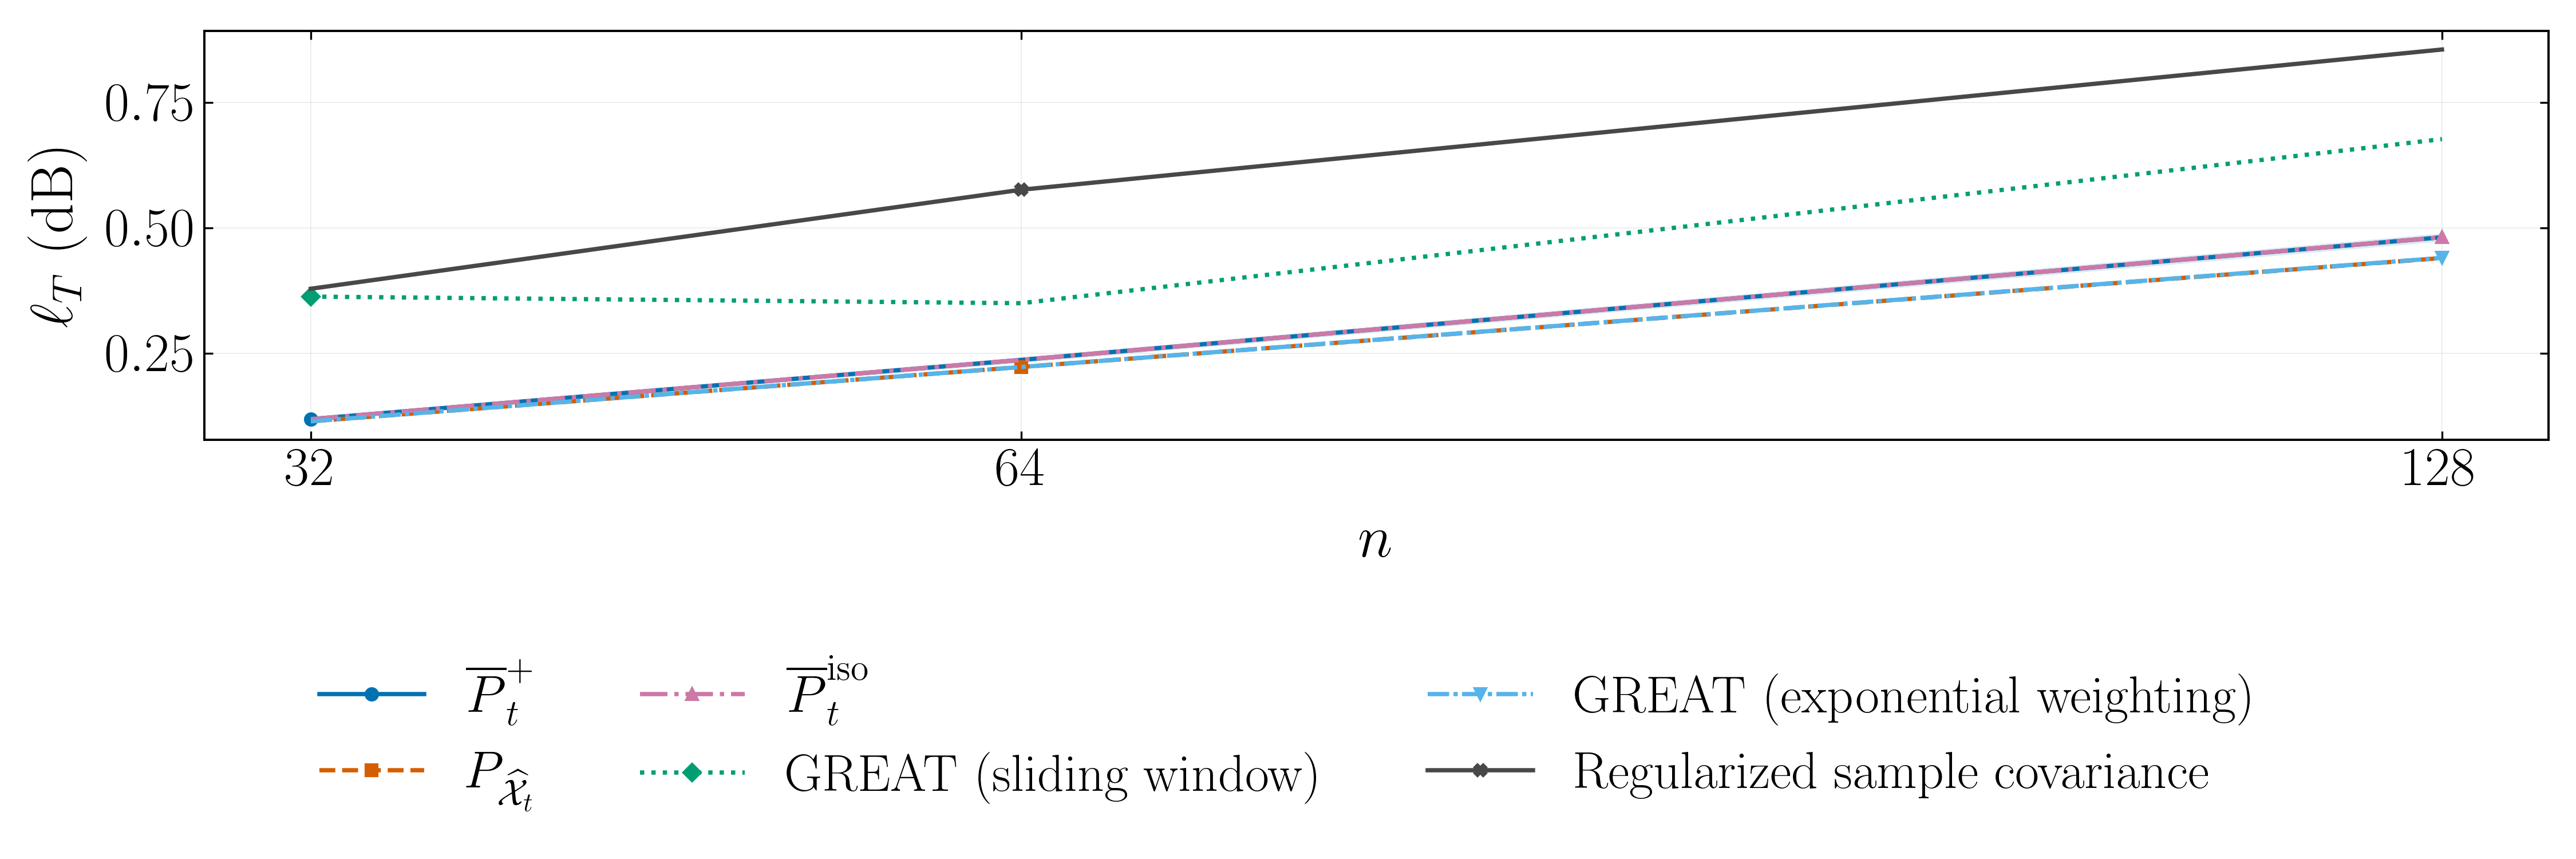

In [3]:
# Edit the canvas, labels, styles and save commands directly in this cell.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'original_settings.pdf'

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'isotropic': r'$\overline P_t^{\mathrm{iso}}$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
    'covariance_loading': 'Regularized sample covariance',
    'modal_loading':'Regularized mode', 'grouse':'GROUSE',
    'ledoit_wolf':'Ledoit--Wolf', 'oracle':'True covariance',
    'great_window_final_db': r'GREAT, $W=\widehat W_n$',
    'great_full_history_final_db': r'GREAT, $W=T$',
    'great_ew_final_db': 'GREAT (exponential weighting)',
    'covariance_loading_final_db': 'Regularized sample covariance',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'isotropic':'#CC79A7',
    'great_window':'#009E73', 'great_ew':'#56B4E9', 'covariance_loading':'#484848',
    'great_window_final_db':'#009E73', 'great_full_history_final_db':'#006747',
    'great_ew_final_db':'#56B4E9', 'covariance_loading_final_db':'#484848'}
MARKERS = {'mean':'o', 'mode':'s', 'isotropic':'^', 'great_window':'D', 'great_ew':'v',
    'covariance_loading':'X', 'great_window_final_db':'D', 'great_full_history_final_db':'P',
    'great_ew_final_db':'v', 'covariance_loading_final_db':'X'}
LINESTYLES = {'mean':'-', 'mode':'--', 'isotropic':'-.', 'great_window':':',
    'great_ew':(0,(5,1,1,1)), 'covariance_loading':'-',
    'great_window_final_db':':', 'great_full_history_final_db':':',
    'great_ew_final_db':(0,(5,1,1,1)), 'covariance_loading_final_db':'-'}
MARK_OFFSETS = {'mean':0, 'mode':1, 'isotropic':2, 'great_window':0, 'great_ew':2,
    'covariance_loading':1, 'great_window_final_db':0,'great_full_history_final_db':0,
    'great_ew_final_db':2,'covariance_loading_final_db':1}

frame = existing['primary_summary']
methods = ['mean','mode','isotropic','great_window','great_ew','covariance_loading']
fig, ax = plt.subplots(figsize=FIGSIZE,dpi=DPI,layout='constrained')
for method in methods:
    group = frame[frame.method.eq(method)].sort_values('n')
    ax.plot(group.n,group['mean'],marker=MARKERS[method],color=COLORS[method],
            linestyle=LINESTYLES[method],markevery=(MARK_OFFSETS[method],3),label=LABELS[method])
    if method == 'mean':ax.fill_between(group.n,group.lower,group.upper,color=COLORS[method],alpha=.14,linewidth=0)
ax.set(xlabel=r'$n$',ylabel=r'$\ell_T$ (dB)')
ax.set_xticks(CONFIG['dimensions'])
ax.grid(color='#BFC4C8',alpha=.30,linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(),loc='outside lower center',ncol=3,frameon=False,fontsize=LEGEND_FONT_SIZE)

# Complete rectangular frames; ticks on all sides, labels only left/bottom.
for _axes in fig.axes:
    for _spine in _axes.spines.values():
        _spine.set_visible(True)
        _spine.set_linewidth(.95)
    _axes.tick_params(direction='in', top=True, right=True, labeltop=False, labelright=False)
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
plt.show()


### Final-measurement validation and observation history

The separate audit selects settings using the mean individual measured dB output power at $t=200$ on the same 64 validation simulations. The test simulations remain independent. Sliding-window GREAT additionally admits the full observation history $W=T=200$. The unrestricted selected window is denoted $\widehat W_n$; a separately selected $W=T$ comparison is retained even when it is not the unrestricted choice. GREAT EW and covariance shrinkage are also selected under this final-measurement criterion.

The posterior mean, mode and isotropic controls below retain their original parameters. Thus an improvement in this section may reflect a more appropriate history or a different measured validation criterion, rather than posterior uncertainty. Exact selected windows, step counts, step sizes and loading parameters are reported in the tables.

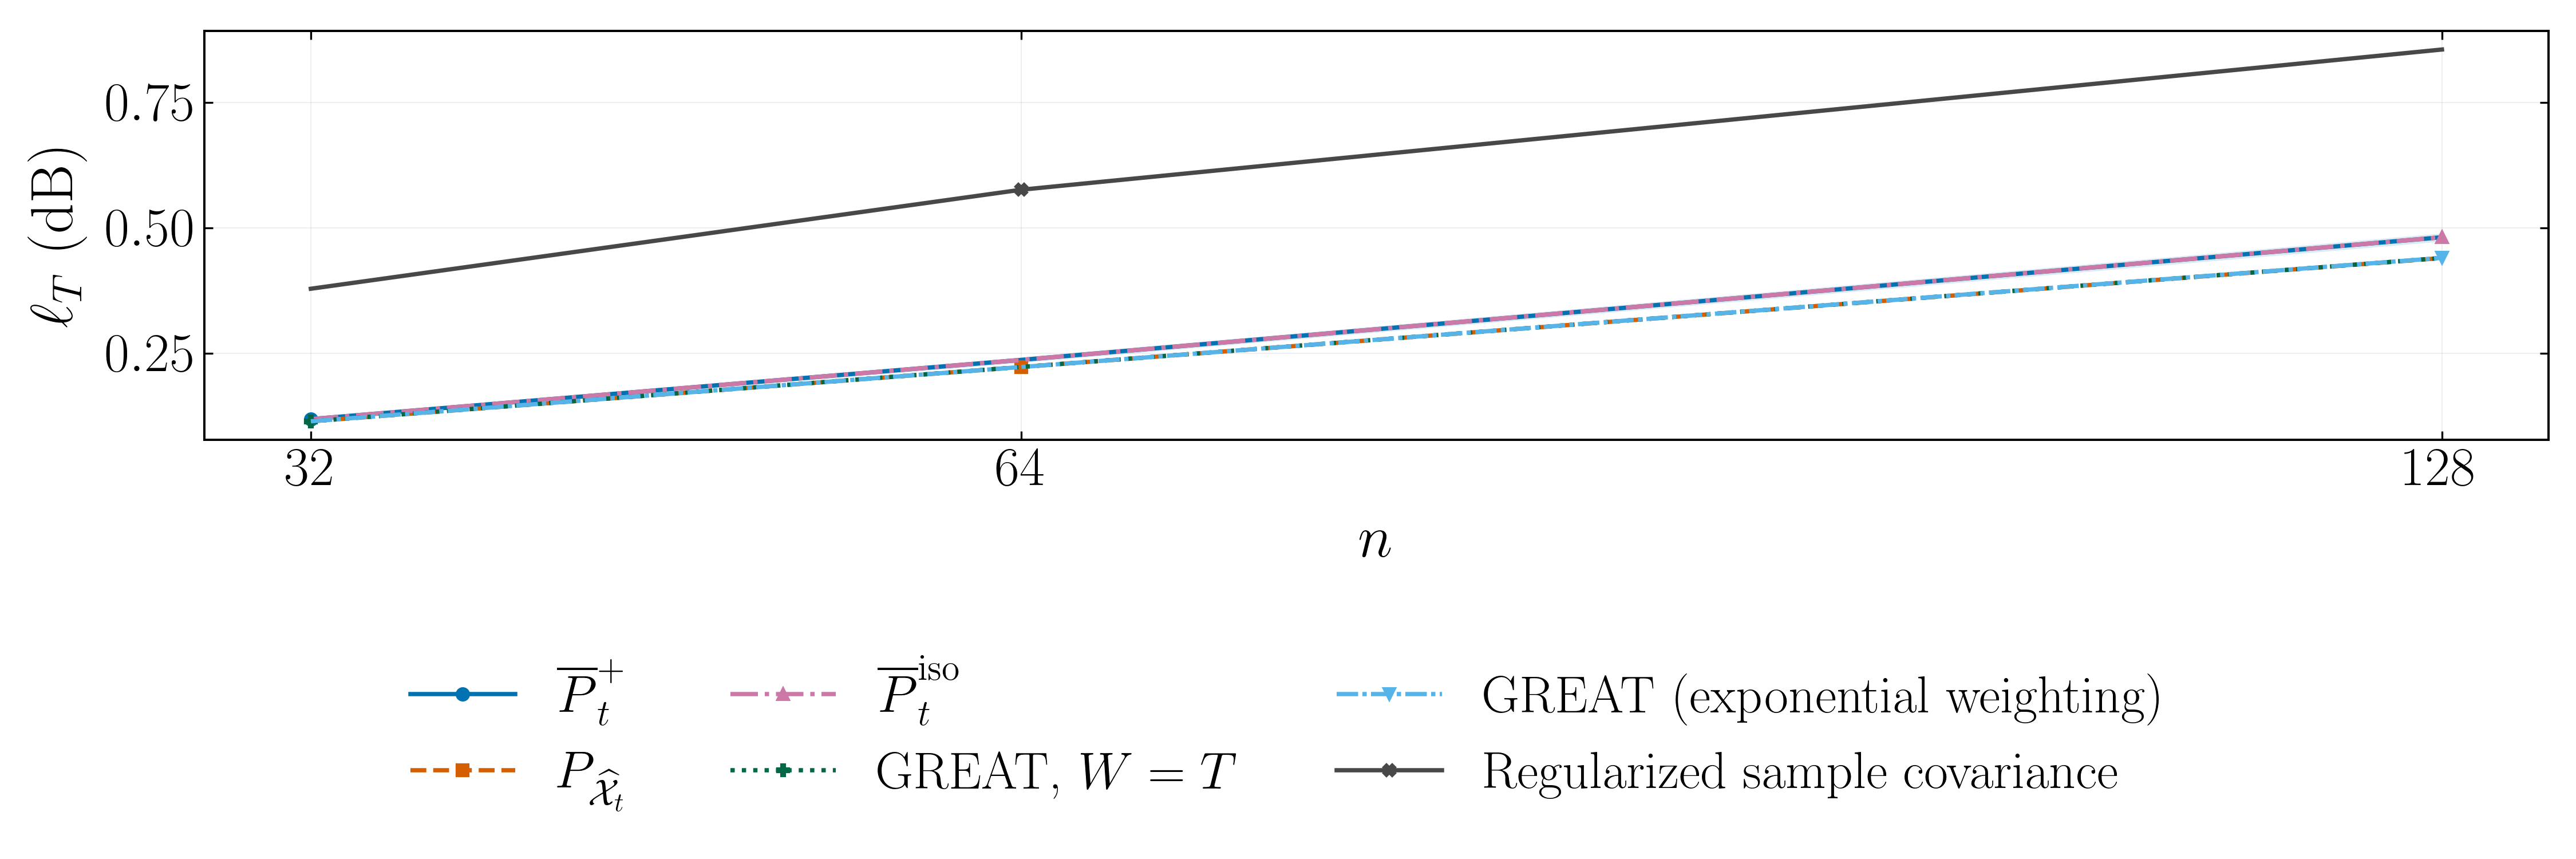

In [4]:
# Edit the canvas, labels, styles and save commands directly in this cell.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'final_time_selection.pdf'

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'isotropic': r'$\overline P_t^{\mathrm{iso}}$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
    'covariance_loading': 'Regularized sample covariance',
    'modal_loading':'Regularized mode', 'grouse':'GROUSE',
    'ledoit_wolf':'Ledoit--Wolf', 'oracle':'True covariance',
    'great_window_final_db': r'GREAT, $W=\widehat W_n$',
    'great_full_history_final_db': r'GREAT, $W=T$',
    'great_ew_final_db': 'GREAT (exponential weighting)',
    'covariance_loading_final_db': 'Regularized sample covariance',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'isotropic':'#CC79A7',
    'great_window':'#009E73', 'great_ew':'#56B4E9', 'covariance_loading':'#484848',
    'great_window_final_db':'#009E73', 'great_full_history_final_db':'#006747',
    'great_ew_final_db':'#56B4E9', 'covariance_loading_final_db':'#484848'}
MARKERS = {'mean':'o', 'mode':'s', 'isotropic':'^', 'great_window':'D', 'great_ew':'v',
    'covariance_loading':'X', 'great_window_final_db':'D', 'great_full_history_final_db':'P',
    'great_ew_final_db':'v', 'covariance_loading_final_db':'X'}
LINESTYLES = {'mean':'-', 'mode':'--', 'isotropic':'-.', 'great_window':':',
    'great_ew':(0,(5,1,1,1)), 'covariance_loading':'-',
    'great_window_final_db':':', 'great_full_history_final_db':':',
    'great_ew_final_db':(0,(5,1,1,1)), 'covariance_loading_final_db':'-'}
MARK_OFFSETS = {'mean':0, 'mode':1, 'isotropic':2, 'great_window':0, 'great_ew':2,
    'covariance_loading':1, 'great_window_final_db':0,'great_full_history_final_db':0,
    'great_ew_final_db':2,'covariance_loading_final_db':1}

frame = selection['test_summary']
methods = ['mean','mode','isotropic','great_window_final_db','great_full_history_final_db',
           'great_ew_final_db','covariance_loading_final_db']
selected_window = frame[frame.method.eq('great_window_final_db')].sort_values('n')
full_history = frame[frame.method.eq('great_full_history_final_db')].sort_values('n')
same_history = all(record['settings']['great_window_final_db']['window'] == 200
                   for record in selection['selected_settings'].values())
if same_history and np.allclose(selected_window[['mean','lower','upper']],full_history[['mean','lower','upper']],rtol=0,atol=1e-10):
    methods.remove('great_window_final_db')  # Same settings; tables retain both records.
fig, ax = plt.subplots(figsize=FIGSIZE,dpi=DPI,layout='constrained')
for method in methods:
    group = frame[frame.method.eq(method)].sort_values('n')
    ax.plot(group.n,group['mean'],marker=MARKERS[method],color=COLORS[method],
            linestyle=LINESTYLES[method],markevery=(MARK_OFFSETS[method],3),label=LABELS[method])
    if method == 'mean':ax.fill_between(group.n,group.lower,group.upper,color=COLORS[method],alpha=.14,linewidth=0)
ax.set(xlabel=r'$n$',ylabel=r'$\ell_T$ (dB)')
ax.set_xticks(CONFIG['dimensions'])
ax.grid(color='#BFC4C8',alpha=.30,linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(),loc='outside lower center',ncol=3,frameon=False,fontsize=LEGEND_FONT_SIZE)

# Complete rectangular frames; ticks on all sides, labels only left/bottom.
for _axes in fig.axes:
    for _spine in _axes.spines.values():
        _spine.set_visible(True)
        _spine.set_linewidth(.95)
    _axes.tick_params(direction='in', top=True, right=True, labeltop=False, labelright=False)
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
plt.show()


The paired display uses $n=64$ at $t=200$, with reference-minus-posterior-mean differences. All three dimensions and all original/new methods, including negative differences, remain in the following tables.

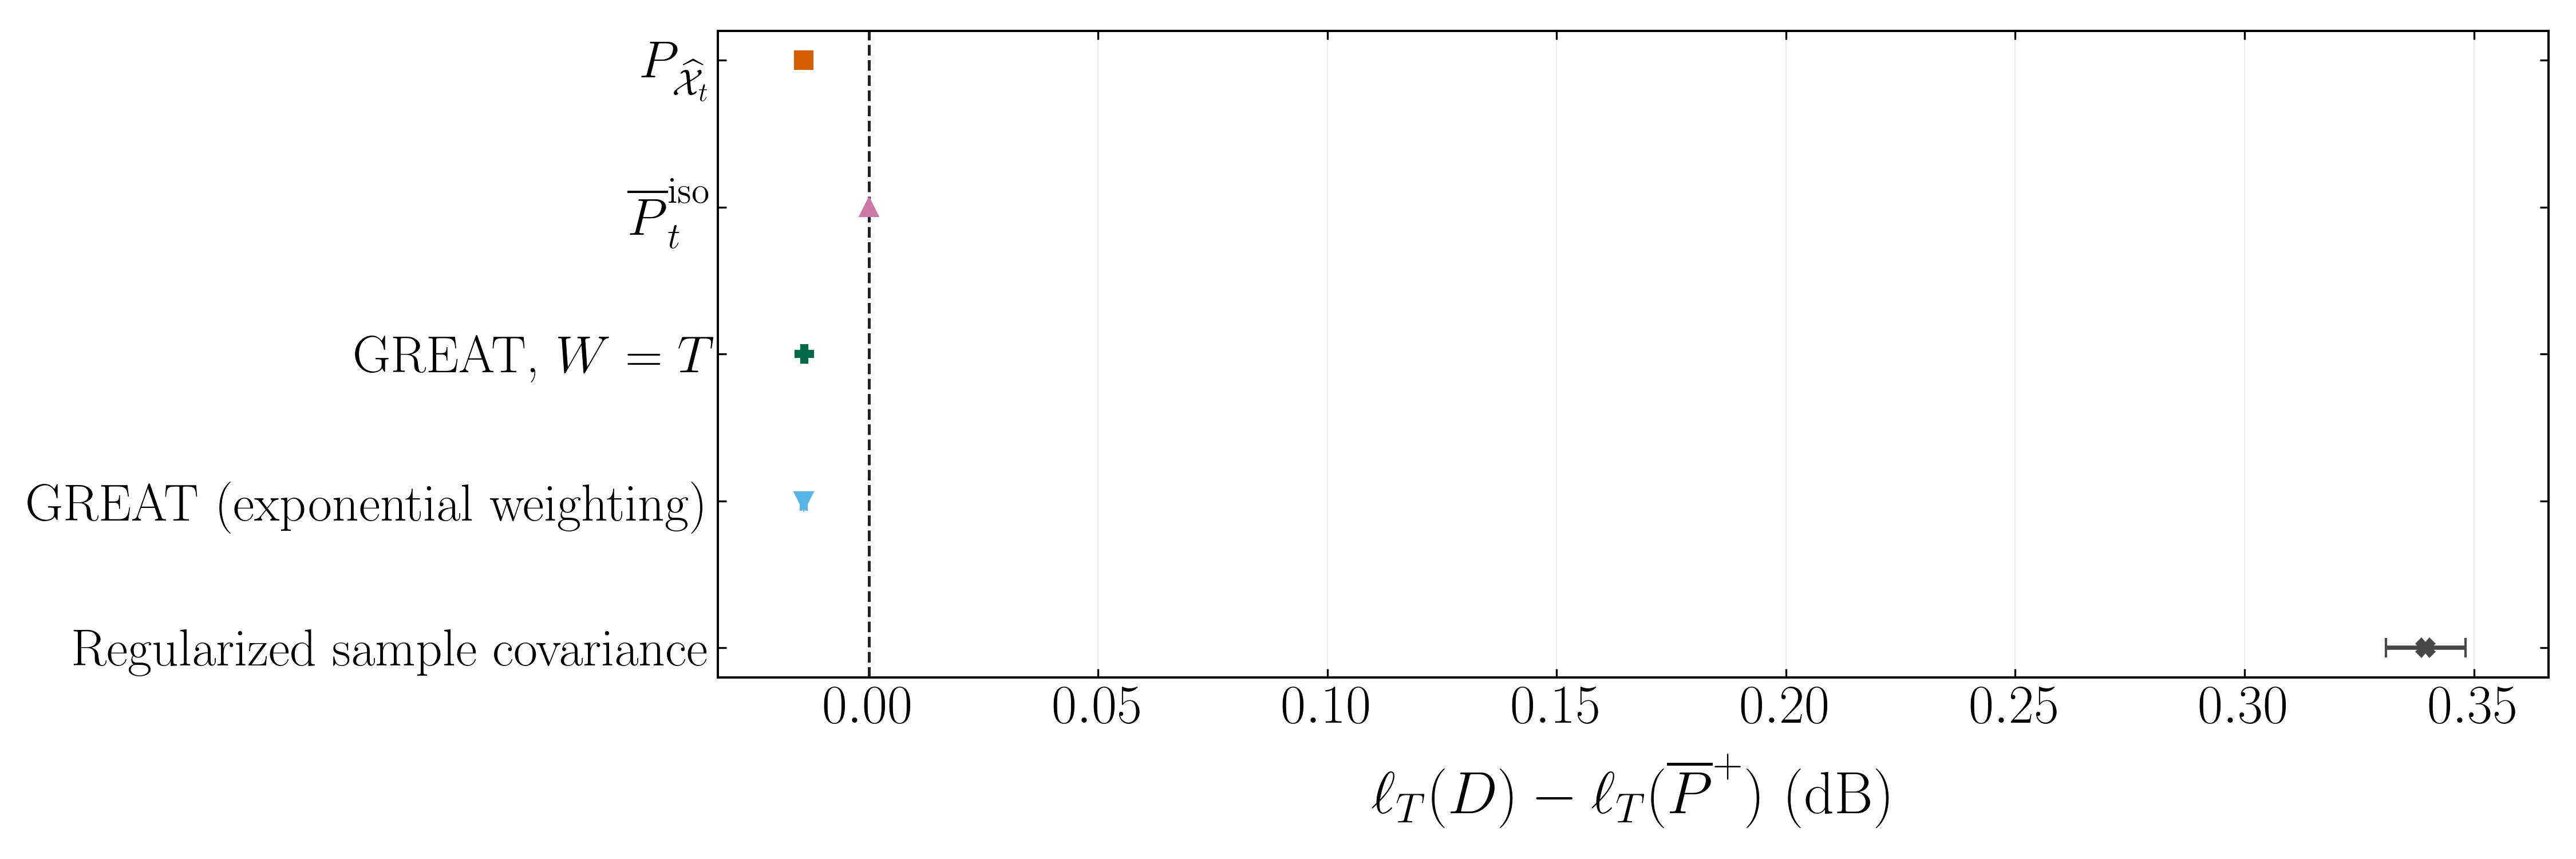

In [5]:
# Edit the canvas, labels, styles and save commands directly in this cell.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'paired_final_time.pdf'

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'isotropic': r'$\overline P_t^{\mathrm{iso}}$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
    'covariance_loading': 'Regularized sample covariance',
    'modal_loading':'Regularized mode', 'grouse':'GROUSE',
    'ledoit_wolf':'Ledoit--Wolf', 'oracle':'True covariance',
    'great_window_final_db': r'GREAT, $W=\widehat W_n$',
    'great_full_history_final_db': r'GREAT, $W=T$',
    'great_ew_final_db': 'GREAT (exponential weighting)',
    'covariance_loading_final_db': 'Regularized sample covariance',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'isotropic':'#CC79A7',
    'great_window':'#009E73', 'great_ew':'#56B4E9', 'covariance_loading':'#484848',
    'great_window_final_db':'#009E73', 'great_full_history_final_db':'#006747',
    'great_ew_final_db':'#56B4E9', 'covariance_loading_final_db':'#484848'}
MARKERS = {'mean':'o', 'mode':'s', 'isotropic':'^', 'great_window':'D', 'great_ew':'v',
    'covariance_loading':'X', 'great_window_final_db':'D', 'great_full_history_final_db':'P',
    'great_ew_final_db':'v', 'covariance_loading_final_db':'X'}
LINESTYLES = {'mean':'-', 'mode':'--', 'isotropic':'-.', 'great_window':':',
    'great_ew':(0,(5,1,1,1)), 'covariance_loading':'-',
    'great_window_final_db':':', 'great_full_history_final_db':':',
    'great_ew_final_db':(0,(5,1,1,1)), 'covariance_loading_final_db':'-'}
MARK_OFFSETS = {'mean':0, 'mode':1, 'isotropic':2, 'great_window':0, 'great_ew':2,
    'covariance_loading':1, 'great_window_final_db':0,'great_full_history_final_db':0,
    'great_ew_final_db':2,'covariance_loading_final_db':1}

frame = selection['paired_vs_mean']
frame = frame[frame.n.eq(64)]
methods = ['mode','isotropic','great_window_final_db','great_full_history_final_db',
           'great_ew_final_db','covariance_loading_final_db']
selected_window = frame[frame.reference.eq('great_window_final_db')].iloc[0]
full_history = frame[frame.reference.eq('great_full_history_final_db')].iloc[0]
same_history = selection['selected_settings']['64']['settings']['great_window_final_db']['window'] == 200
if same_history and np.allclose(selected_window[['mean','lower','upper']].to_numpy(dtype=float),
               full_history[['mean','lower','upper']].to_numpy(dtype=float),rtol=0,atol=1e-10):
    methods.remove('great_window_final_db')
fig, ax = plt.subplots(figsize=FIGSIZE,dpi=DPI,layout='constrained')
labels=[]
for method in methods:
    row = frame[frame.reference.eq(method)].iloc[0]
    position=len(labels);labels.append(LABELS[method])
    ax.errorbar(row['mean'],position,
        xerr=[[row['mean']-row['lower']],[row['upper']-row['mean']]],
        fmt=MARKERS[method],color=COLORS[method],capsize=4.,markersize=7.)
ax.axvline(0.,color='#222222',linestyle='--',linewidth=1.2)
ax.set(yticks=np.arange(len(labels)),yticklabels=labels,
       xlabel=r'$\ell_T(D)-\ell_T(\overline P^+)$ (dB)')
ax.tick_params(axis='y',labelsize=LEGEND_FONT_SIZE)
ax.invert_yaxis()
ax.grid(axis='x',color='#BFC4C8',alpha=.30,linewidth=.45)

# Complete rectangular frames; ticks on all sides, labels only left/bottom.
for _axes in fig.axes:
    for _spine in _axes.spines.values():
        _spine.set_visible(True)
        _spine.set_linewidth(.95)
    _axes.tick_params(direction='in', top=True, right=True, labeltop=False, labelright=False)
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
plt.show()


In [6]:
LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'isotropic': r'$\overline P_t^{\mathrm{iso}}$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
    'covariance_loading': 'Regularized sample covariance',
    'modal_loading':'Regularized mode', 'grouse':'GROUSE',
    'ledoit_wolf':'Ledoit--Wolf', 'oracle':'True covariance',
    'great_window_final_db': r'GREAT, $W=\widehat W_n$',
    'great_full_history_final_db': r'GREAT, $W=T$',
    'great_ew_final_db': 'GREAT (exponential weighting)',
    'covariance_loading_final_db': 'Regularized sample covariance',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'isotropic':'#CC79A7',
    'great_window':'#009E73', 'great_ew':'#56B4E9', 'covariance_loading':'#484848',
    'great_window_final_db':'#009E73', 'great_full_history_final_db':'#006747',
    'great_ew_final_db':'#56B4E9', 'covariance_loading_final_db':'#484848'}
MARKERS = {'mean':'o', 'mode':'s', 'isotropic':'^', 'great_window':'D', 'great_ew':'v',
    'covariance_loading':'X', 'great_window_final_db':'D', 'great_full_history_final_db':'P',
    'great_ew_final_db':'v', 'covariance_loading_final_db':'X'}
LINESTYLES = {'mean':'-', 'mode':'--', 'isotropic':'-.', 'great_window':':',
    'great_ew':(0,(5,1,1,1)), 'covariance_loading':'-',
    'great_window_final_db':':', 'great_full_history_final_db':':',
    'great_ew_final_db':(0,(5,1,1,1)), 'covariance_loading_final_db':'-'}
MARK_OFFSETS = {'mean':0, 'mode':1, 'isotropic':2, 'great_window':0, 'great_ew':2,
    'covariance_loading':1, 'great_window_final_db':0,'great_full_history_final_db':0,
    'great_ew_final_db':2,'covariance_loading_final_db':1}

# Original settings and the new final-time criterion remain separate.
original = existing['primary_summary'].copy()
original['method'] = original.method.map(LABELS)
original_pairs = existing['paired_primary_summary'].copy()
original_pairs['reference'] = original_pairs.reference.map(LABELS)
display(HTML('<details><summary>All original final-measurement means</summary>'+
    original.to_html(index=False,escape=False,float_format=lambda value:f'{value:.6g}')+'</details>'))
display(HTML('<details><summary>All original paired differences</summary>'+
    original_pairs.to_html(index=False,escape=False,float_format=lambda value:f'{value:.6g}')+'</details>'))
rows=[]
for n, record in selection['selected_settings'].items():
    for method, parameters in record['settings'].items():
        rows.append({'n':int(n),'method':LABELS[method],
            **{name:parameters.get(name,np.nan) for name in
               ['window','inner_steps','beta','stepsize','step_multiplier','alpha','validation_mean_db']}})
display(HTML('<details><summary>Actual settings selected by the final-measurement criterion</summary>'+
    pd.DataFrame(rows).to_html(index=False,escape=False,float_format=lambda value:f'{value:.6g}')+'</details>'))
new_summary = selection['test_summary'].copy()
new_summary['method'] = new_summary.method.map(LABELS)
new_pairs = selection['paired_vs_mean'].copy()
new_pairs['reference'] = new_pairs.reference.map(LABELS)
display(HTML('<details><summary>All final-time-selection means, including original references</summary>'+
    new_summary.to_html(index=False,escape=False,float_format=lambda value:f'{value:.6g}')+'</details>'))
display(HTML('<details><summary>All paired final-time-selection differences</summary>'+
    new_pairs.to_html(index=False,escape=False,float_format=lambda value:f'{value:.6g}')+'</details>'))
if all(record['settings']['great_window_final_db']['window'] == 200
       for record in selection['selected_settings'].values()):
    display(Markdown('The unrestricted selected window is $W=200$ at every dimension. It coincides '
        'with the explicit full-history comparison, so only one of these identical curves is drawn. '
        'Both audit records remain in the tables.'))
means=selection['test_summary'].pivot(index='n',columns='method',values='mean')
comparison=means[['mean','mode','great_window','great_full_history_final_db','great_ew_final_db']].copy()
comparison.columns=['Posterior mean','Mode','Original sliding window','Full history W=200','GREAT EW (final-time criterion)']
display(comparison)
if all(means['great_full_history_final_db'] < means['mean']):
    display(Markdown('With matched full observation history, GREAT has lower mean final-measurement '
        'dB loss than the posterior mean at every dimension in this fixed generating cohort. '
        'The substantial original sliding-window gap largely disappears. This identifies observation '
        'history as an important confound in that comparison; it does not contradict the posterior '
        'expected-linear-power decision rule.'))
linear_rows=[]
for (n,method), group in selection['test_metrics'].groupby(['n','method'],sort=True):
    values=(group.true_power/group.oracle_power).to_numpy()
    mean=values.mean()
    half=student_t.ppf(.975,len(values)-1)*values.std(ddof=1)/np.sqrt(len(values))
    linear_rows.append({'n':n,'method':method,'mean linear ratio':mean,
                       'lower':mean-half,'upper':mean+half,'simulations':len(values)})
linear_summary=pd.DataFrame(linear_rows)
display(HTML('<details><summary>Mean linear power ratios: a separate test risk</summary>'+
    linear_summary.to_html(index=False,float_format=lambda value:f'{value:.6g}')+'</details>'))
EDITABLE_OUTPUT.mkdir(parents=True,exist_ok=True)
linear_summary.to_csv(EDITABLE_OUTPUT/'linear_power_summary.csv',index=False)


n,t,method,simulations,mean,lower,upper
32,200,Regularized sample covariance,256,0.378834,0.369074,0.388595
32,200,GREAT (exponential weighting),256,0.114385,0.110873,0.117897
32,200,GREAT (sliding window),256,0.363181,0.351389,0.374973
32,200,GROUSE,256,1.11236,1.08589,1.13884
32,200,$\overline P_t^{\mathrm{iso}}$,256,0.118795,0.115125,0.122465
32,200,Ledoit--Wolf,256,0.43322,0.42334,0.4431
32,200,$\overline P_t^+$,256,0.118789,0.115119,0.122459
32,200,Regularized mode,256,0.114388,0.110875,0.117901
32,200,$P_{\widehat{\mathcal X}_t}$,256,0.114388,0.110875,0.117901
32,200,True covariance,256,0,0,0


n,t,reference,gain,simulations,mean,lower,upper
32,200,$P_{\widehat{\mathcal X}_t}$,-0.00440153,256,-0.00440153,-0.00479222,-0.00401084
32,200,$\overline P_t^{\mathrm{iso}}$,6.00672e-06,256,6.00672e-06,-3.78049e-06,1.57939e-05
32,200,Regularized mode,-0.00440153,256,-0.00440153,-0.00479222,-0.00401084
32,200,Regularized sample covariance,0.260045,256,0.260045,0.251774,0.268316
32,200,GREAT (sliding window),0.244392,256,0.244392,0.233678,0.255106
32,200,GREAT (exponential weighting),-0.00440374,256,-0.00440374,-0.00479443,-0.00401305
32,200,GROUSE,0.993573,256,0.993573,0.967501,1.01964
32,200,Ledoit--Wolf,0.314431,256,0.314431,0.305024,0.323837
32,200,True covariance,-0.118789,256,-0.118789,-0.122459,-0.115119
64,200,$P_{\widehat{\mathcal X}_t}$,-0.014184,256,-0.014184,-0.0147901,-0.013578


n,method,window,inner_steps,beta,stepsize,step_multiplier,alpha,validation_mean_db
32,"GREAT, $W=\widehat W_n$",200,3,NaN,0.001,0.24,NaN,-4.57283
32,GREAT (exponential weighting),NaN,3,1,0.00104167,0.08,NaN,-4.57282
32,"GREAT, $W=T$",200,3,NaN,0.001,0.24,NaN,-4.57283
32,Regularized sample covariance,NaN,NaN,1,NaN,NaN,0.354214,-4.32758
64,"GREAT, $W=\widehat W_n$",200,3,NaN,0.001,0.24,NaN,-4.39219
64,GREAT (exponential weighting),NaN,3,1,0.0015625,0.24,NaN,-4.39228
64,"GREAT, $W=T$",200,3,NaN,0.001,0.24,NaN,-4.39219
64,Regularized sample covariance,NaN,NaN,1,NaN,NaN,0.459181,-4.04364
128,"GREAT, $W=\widehat W_n$",200,3,NaN,0.001,0.24,NaN,-4.22996
128,GREAT (exponential weighting),NaN,3,1,0.00078125,0.24,NaN,-4.22978


n,t,method,simulations,mean,lower,upper
32,200,Regularized sample covariance,256,0.378834,0.369074,0.388595
32,200,Regularized sample covariance,256,0.378834,0.369071,0.388597
32,200,GREAT (exponential weighting),256,0.114385,0.110873,0.117897
32,200,GREAT (exponential weighting),256,0.114435,0.110918,0.117952
32,200,"GREAT, $W=T$",256,0.114442,0.110925,0.11796
32,200,GREAT (sliding window),256,0.363181,0.351389,0.374973
32,200,"GREAT, $W=\widehat W_n$",256,0.114442,0.110925,0.11796
32,200,GROUSE,256,1.11236,1.08589,1.13884
32,200,$\overline P_t^{\mathrm{iso}}$,256,0.118795,0.115125,0.122465
32,200,Ledoit--Wolf,256,0.43322,0.42334,0.4431


n,t,reference,simulations,mean,lower,upper,sign
32,200,Regularized sample covariance,256,0.260045,0.251774,0.268316,Reference minus original posterior mean; positive favors posterior mean
32,200,Regularized sample covariance,256,0.260045,0.251774,0.268316,Reference minus original posterior mean; positive favors posterior mean
32,200,GREAT (exponential weighting),256,-0.00440374,-0.00479443,-0.00401305,Reference minus original posterior mean; positive favors posterior mean
32,200,GREAT (exponential weighting),256,-0.00435394,-0.0047479,-0.00395998,Reference minus original posterior mean; positive favors posterior mean
32,200,"GREAT, $W=T$",256,-0.00434682,-0.00474172,-0.00395192,Reference minus original posterior mean; positive favors posterior mean
32,200,GREAT (sliding window),256,0.244392,0.233678,0.255106,Reference minus original posterior mean; positive favors posterior mean
32,200,"GREAT, $W=\widehat W_n$",256,-0.00434682,-0.00474172,-0.00395192,Reference minus original posterior mean; positive favors posterior mean
32,200,GROUSE,256,0.993573,0.967501,1.01964,Reference minus original posterior mean; positive favors posterior mean
32,200,$\overline P_t^{\mathrm{iso}}$,256,6.00672e-06,-3.78049e-06,1.57939e-05,Reference minus original posterior mean; positive favors posterior mean
32,200,Ledoit--Wolf,256,0.314431,0.305024,0.323837,Reference minus original posterior mean; positive favors posterior mean


The unrestricted selected window is $W=200$ at every dimension. It coincides with the explicit full-history comparison, so only one of these identical curves is drawn. Both audit records remain in the tables.

,Posterior mean,Mode,Original sliding window,Full history W=200,GREAT EW (final-time criterion)
n,,,,,
32,0.118789,0.114388,0.363181,0.114442,0.114435
64,0.236885,0.222701,0.349989,0.222805,0.222710
128,0.481558,0.440108,0.677332,0.440277,0.440442


With matched full observation history, GREAT has lower mean final-measurement dB loss than the posterior mean at every dimension in this fixed generating cohort. The substantial original sliding-window gap largely disappears. This identifies observation history as an important confound in that comparison; it does not contradict the posterior expected-linear-power decision rule.

n,method,mean linear ratio,lower,upper,simulations
32,covariance_loading,1.09133,1.08887,1.09379,256
32,covariance_loading_final_db,1.09133,1.08887,1.09379,256
32,great_ew,1.02671,1.02588,1.02755,256
32,great_ew_final_db,1.02672,1.02589,1.02756,256
32,great_full_history_final_db,1.02672,1.02589,1.02756,256
32,great_window,1.08749,1.0845,1.09047,256
32,great_window_final_db,1.02672,1.02589,1.02756,256
32,grouse,1.29351,1.28553,1.3015,256
32,isotropic,1.02776,1.02688,1.02863,256
32,ledoit_wolf,1.10509,1.10256,1.10761,256


## Independent memory selection for the posterior mean

This audit searches only the original grid $\beta\in\{1,0.99,0.97,0.9\}$. Define $\widehat V(\beta)$ as the average measured dB output power across validation simulations, averaging the primary reporting measurements inside each simulation. For moving data these are all 32 reports; for stationary data only $t=200$ is used. The minimum on the validation grid selects $\widehat\beta$. Test data and secondary outcomes do not participate in selection.

The open marker identifies the selected grid point. The labels give its actual $\widehat\beta$. Confidence bands summarize validation-simulation variability and do not change the selection rule.

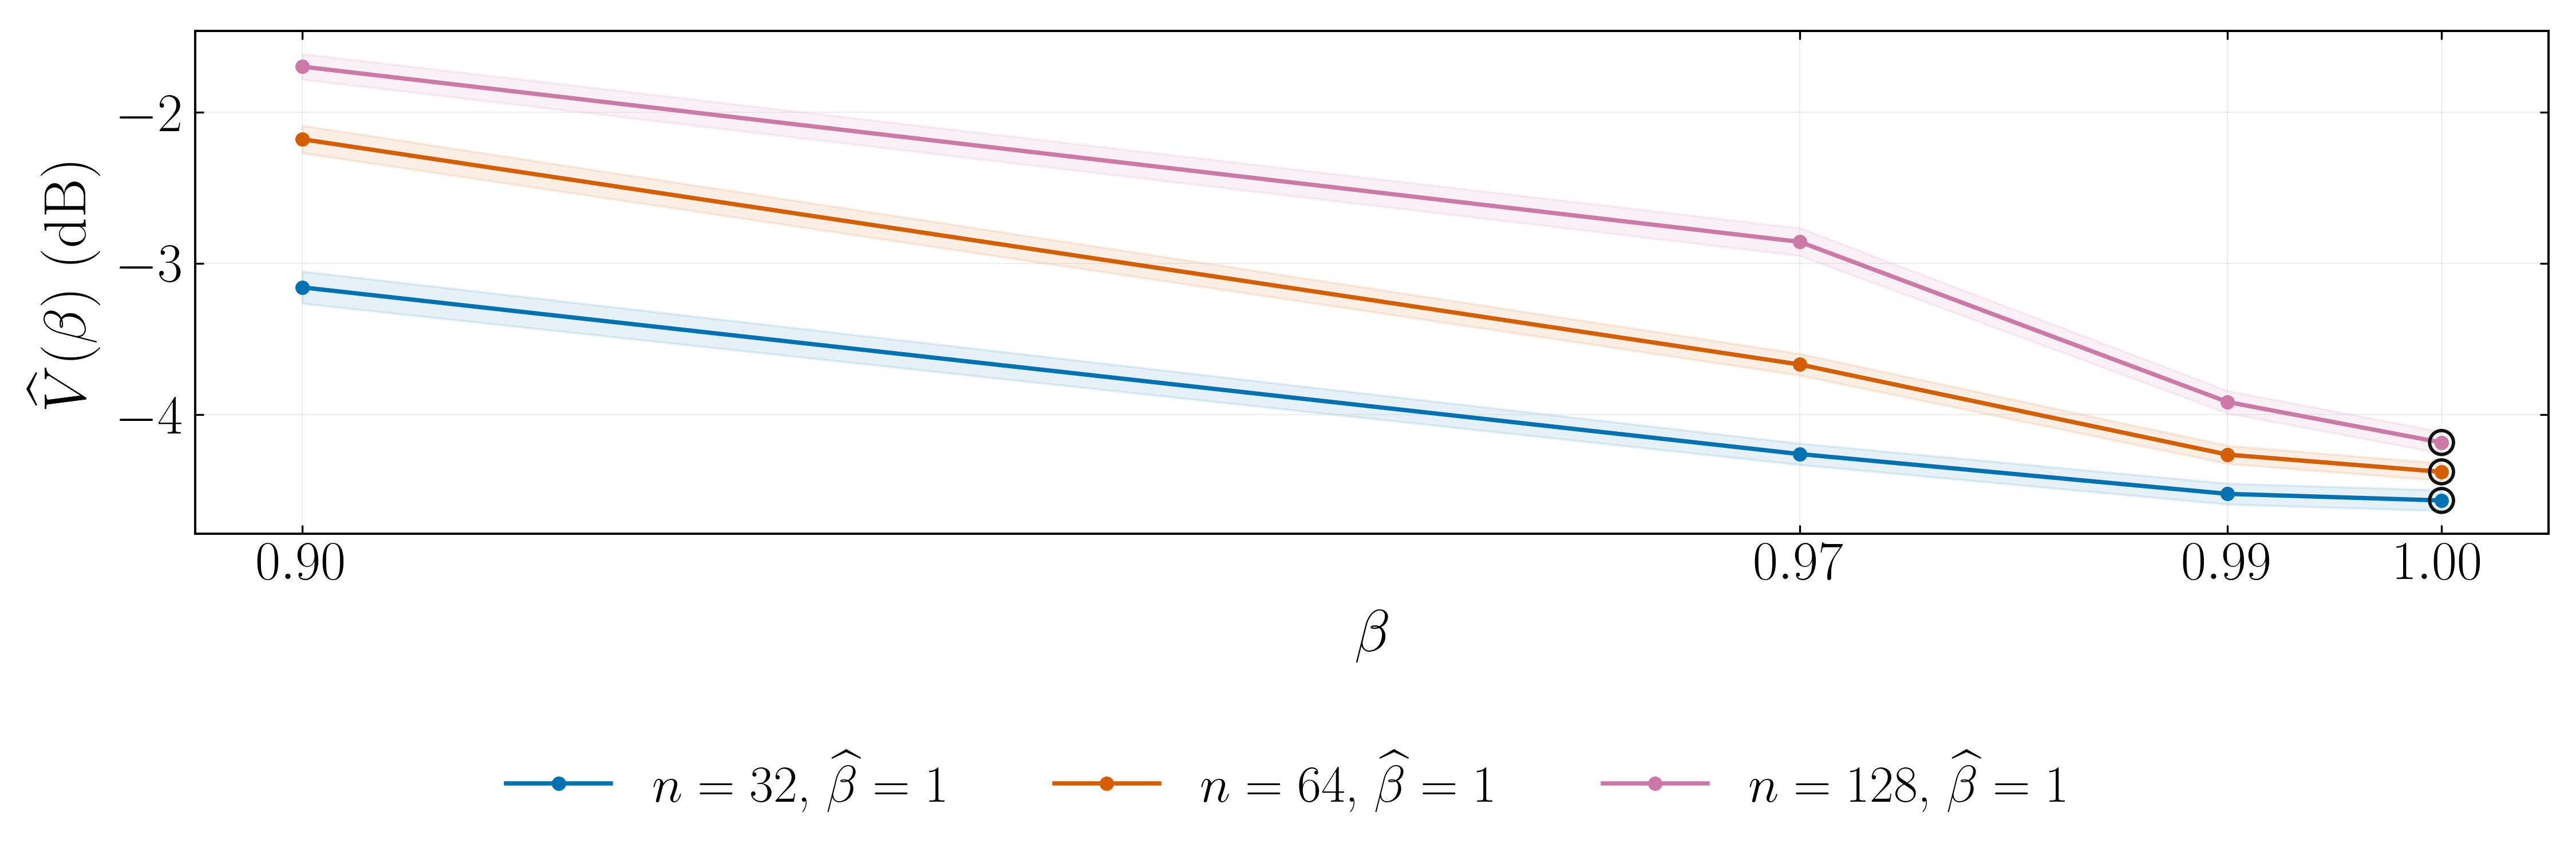

In [7]:
# Edit the canvas, labels, styles and save commands directly in this cell.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'posterior_mean_beta.pdf'

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'isotropic': r'$\overline P_t^{\mathrm{iso}}$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
    'covariance_loading': 'Regularized sample covariance',
    'modal_loading':'Regularized mode', 'grouse':'GROUSE',
    'ledoit_wolf':'Ledoit--Wolf', 'oracle':'True covariance',
    'great_window_final_db': r'GREAT, $W=\widehat W_n$',
    'great_full_history_final_db': r'GREAT, $W=T$',
    'great_ew_final_db': 'GREAT (exponential weighting)',
    'covariance_loading_final_db': 'Regularized sample covariance',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'isotropic':'#CC79A7',
    'great_window':'#009E73', 'great_ew':'#56B4E9', 'covariance_loading':'#484848',
    'great_window_final_db':'#009E73', 'great_full_history_final_db':'#006747',
    'great_ew_final_db':'#56B4E9', 'covariance_loading_final_db':'#484848'}
MARKERS = {'mean':'o', 'mode':'s', 'isotropic':'^', 'great_window':'D', 'great_ew':'v',
    'covariance_loading':'X', 'great_window_final_db':'D', 'great_full_history_final_db':'P',
    'great_ew_final_db':'v', 'covariance_loading_final_db':'X'}
LINESTYLES = {'mean':'-', 'mode':'--', 'isotropic':'-.', 'great_window':':',
    'great_ew':(0,(5,1,1,1)), 'covariance_loading':'-',
    'great_window_final_db':':', 'great_full_history_final_db':':',
    'great_ew_final_db':(0,(5,1,1,1)), 'covariance_loading_final_db':'-'}
MARK_OFFSETS = {'mean':0, 'mode':1, 'isotropic':2, 'great_window':0, 'great_ew':2,
    'covariance_loading':1, 'great_window_final_db':0,'great_full_history_final_db':0,
    'great_ew_final_db':2,'covariance_loading_final_db':1}

frame = mean_audit['validation_scores']
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
cases = list(frame[['condition','n']].drop_duplicates().itertuples(index=False,name=None))
palette = ['#0072B2','#D55E00','#CC79A7']
for index, (condition,n) in enumerate(cases):
    subset = frame[frame.condition.eq(condition) & frame.n.eq(n)]
    points = []
    for beta, group in subset.groupby('beta',sort=True):
        # One validation loss per independent simulation; reporting times average inside it.
        values = group.groupby('trial').measured_power_db.mean().to_numpy()
        mean = values.mean()
        half = student_t.ppf(.975,len(values)-1)*values.std(ddof=1)/np.sqrt(len(values))
        points.append([beta,mean,mean-half,mean+half])
    points = np.asarray(points)
    key = condition if SCOPE == 'moving' else 'n'+str(int(n))
    selected_beta = float(mean_audit['selection'][key]['selected_beta'])
    case_label = condition.capitalize() if SCOPE == 'moving' else r'$n='+str(int(n))+r'$'
    label = case_label+', '+r'$\widehat\beta='+f'{selected_beta:g}'+r'$'
    ax.plot(points[:,0],points[:,1], 'o-', color=palette[index],label=label)
    ax.fill_between(points[:,0],points[:,2],points[:,3],color=palette[index],alpha=.10)
    selected = points[np.isclose(points[:,0],selected_beta)][0]
    ax.scatter(selected[0],selected[1],s=100,facecolors='none',edgecolors='#111111',linewidths=1.4,zorder=5)
ax.set(xlabel=r'$\beta$', ylabel=r'$\widehat V(\beta)$ (dB)')
ax.set_xticks(sorted(frame.beta.unique()))
ax.grid(color='#BFC4C8', alpha=.30, linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(), loc='outside lower center',
           ncol=3 if SCOPE == 'stationary' else 2, frameon=False, fontsize=LEGEND_FONT_SIZE)

# Complete rectangular frames; ticks on all sides, labels only left/bottom.
for _axes in fig.axes:
    for _spine in _axes.spines.values():
        _spine.set_visible(True)
        _spine.set_linewidth(.95)
    _axes.tick_params(direction='in', top=True, right=True, labeltop=False, labelright=False)
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
plt.show()


In [8]:
baseline = float(mean_audit['config']['baseline_beta'])
choices = {case:float(value['selected_beta']) for case,value in mean_audit['selection'].items()}
if all(np.isclose(value,baseline) for value in choices.values()):
    display(Markdown('The independent posterior-mean searches select the existing '+
        r'$\beta='+f'{baseline:g}'+r'$ in every case. The corresponding test records are reused exactly; '
        'there is no additional posterior-mean curve or improved method to report.'))
    display(Markdown('Differences below $10^{-10}$ dB in repeated CSV summaries are round-trip '
        'precision, not an advantage or a separately resolved confidence-interval result.'))
else:
    display(Markdown('The independently selected memory is a separate comparison. It changes the '
        'posterior parameter, so its difference from a common-memory mode is not solely an uncertainty effect.'))
summary = mean_audit['summary']
summary = summary[summary.endpoint.eq('true_ratio_db')].copy()
paired = mean_audit['paired'].copy()
paired = paired[paired.endpoint.eq('true_ratio_db')]
for table in [summary,paired]:
    for field in ['policy','reference_policy']:
        if field in table:
            table[field] = table[field].replace({'preserved_common':'Original common memory',
                'independently_selected':'Independent mean validation'})
    for field in ['method','reference']:
        if field in table:table[field] = table[field].map(LABELS)
summary = summary.rename(columns={'policy':'Memory choice'})
paired = paired.rename(columns={'policy':'Memory choice','reference_policy':'Reference memory',
                               'mean_difference':'Difference (dB)'})
display(pd.DataFrame([{'case':case,'original beta':baseline,'selected beta':beta,
    'same setting':bool(np.isclose(beta,baseline))} for case,beta in choices.items()]))
display(HTML('<details><summary>All mean-selection test summaries and secondary aggregations</summary>'+
    summary.to_html(index=False,float_format=lambda value:f'{value:.6g}')+'</details>'))
display(HTML('<details><summary>All paired mean-selection comparisons and secondary aggregations</summary>'+
    paired.to_html(index=False,float_format=lambda value:f'{value:.6g}')+'</details>'))


The independent posterior-mean searches select the existing $\beta=1$ in every case. The corresponding test records are reused exactly; there is no additional posterior-mean curve or improved method to report.

Differences below $10^{-10}$ dB in repeated CSV summaries are round-trip precision, not an advantage or a separately resolved confidence-interval result.

,case,original beta,selected beta,same setting
0,n32,1.0,1.0,True
1,n64,1.0,1.0,True
2,n128,1.0,1.0,True


n,condition,Memory choice,method,aggregation,beta,endpoint,mean,lower,upper,standard_error,simulations,degrees_of_freedom
32,static,Original common memory,$\overline P_t^+$,all_mean_db,1,true_ratio_db,0.118789,0.115119,0.122459,0.00186364,256,255
32,static,Original common memory,$P_{\widehat{\mathcal X}_t}$,all_mean_db,1,true_ratio_db,0.114388,0.110875,0.117901,0.00178385,256,255
32,static,Original common memory,$\overline P_t^{\mathrm{iso}}$,all_mean_db,1,true_ratio_db,0.118795,0.115125,0.122465,0.00186373,256,255
32,static,Original common memory,Regularized mode,all_mean_db,1,true_ratio_db,0.114388,0.110875,0.117901,0.00178385,256,255
32,static,Original common memory,Regularized sample covariance,all_mean_db,1,true_ratio_db,0.378834,0.369074,0.388595,0.00495625,256,255
32,static,Original common memory,GREAT (sliding window),all_mean_db,NaN,true_ratio_db,0.363181,0.351389,0.374973,0.00598811,256,255
32,static,Original common memory,GREAT (exponential weighting),all_mean_db,1,true_ratio_db,0.114385,0.110873,0.117897,0.00178331,256,255
32,static,Original common memory,GROUSE,all_mean_db,NaN,true_ratio_db,1.11236,1.08589,1.13884,0.0134442,256,255
32,static,Original common memory,Ledoit--Wolf,all_mean_db,1,true_ratio_db,0.43322,0.42334,0.4431,0.00501689,256,255
32,static,Original common memory,True covariance,all_mean_db,NaN,true_ratio_db,0,0,0,0,256,255


n,condition,aggregation,Memory choice,Reference memory,reference,comparison,endpoint,Difference (dB),lower,upper,standard_error,simulations,degrees_of_freedom
32,static,all_mean_db,Original common memory,Original common memory,$P_{\widehat{\mathcal X}_t}$,same_policy,true_ratio_db,-0.00440153,-0.00479222,-0.00401084,0.00019839,256,255
32,static,all_mean_db,Original common memory,Original common memory,$\overline P_t^{\mathrm{iso}}$,same_policy,true_ratio_db,6.00672e-06,-3.78049e-06,1.57939e-05,4.96986e-06,256,255
32,static,all_mean_db,Original common memory,Original common memory,Regularized mode,same_policy,true_ratio_db,-0.00440153,-0.00479222,-0.00401084,0.00019839,256,255
32,static,all_mean_db,Original common memory,Original common memory,Regularized sample covariance,same_policy,true_ratio_db,0.260045,0.251774,0.268316,0.00419981,256,255
32,static,all_mean_db,Original common memory,Original common memory,GREAT (sliding window),same_policy,true_ratio_db,0.244392,0.233678,0.255106,0.0054406,256,255
32,static,all_mean_db,Original common memory,Original common memory,GREAT (exponential weighting),same_policy,true_ratio_db,-0.00440374,-0.00479443,-0.00401305,0.000198389,256,255
32,static,all_mean_db,Original common memory,Original common memory,GROUSE,same_policy,true_ratio_db,0.993573,0.967501,1.01964,0.0132392,256,255
32,static,all_mean_db,Original common memory,Original common memory,Ledoit--Wolf,same_policy,true_ratio_db,0.314431,0.305024,0.323837,0.00477659,256,255
32,static,all_mean_db,Original common memory,Original common memory,True covariance,same_policy,true_ratio_db,-0.118789,-0.122459,-0.115119,0.00186364,256,255
32,static,all_mean_db,Independent mean validation,Independent mean validation,$P_{\widehat{\mathcal X}_t}$,same_policy,true_ratio_db,-0.00440153,-0.00479222,-0.00401084,0.00019839,256,255


## EW objective, convergence and task loss

Let $C_t=\beta C_{t-1}+\widetilde u_t\widetilde u_t^H$ be the covariance statistic of the likelihood-scaled observations used by GREAT EW. Under the common uniform-prior, fixed-scale construction, its dominant eigenspace equals the mode of the Bingham parameter: adding a scalar identity matrix or multiplying by a positive scalar does not change that eigenspace. This is an equality of objectives. A finite number of gradient steps need not attain that mode.

For the current unit GREAT vector $x_t$, define the scaled Rayleigh gap
\[
\delta_t=\frac{\lambda_{\max}(C_t)-x_t^HC_tx_t}{\lambda_{\max}(C_t)-\lambda_{\min}(C_t)}.
\]
The exact mode has $\delta_t=0$. The reported chordal discrepancy is $d_c(P_{x_t},P_{\widehat{\mathcal X}_t})=\sqrt{1-|x_t^H\widehat x_t|^2}$, a distance to the exact modal eigenspace, not an estimation error against the generating subspace. With ordered eigenvalues $\lambda_1\ge\cdots\ge\lambda_n$ of $C_t$, the unscaled gap $g_t=\lambda_1-x_t^HC_tx_t$ satisfies
\[
(\lambda_1-\lambda_2)d_c^2\le g_t\le(\lambda_1-\lambda_n)d_c^2.
\]
A small scaled objective gap need not imply a small direction error when the leading eigengap is small. Optimizing the EW residual also does not guarantee the lowest true output power. The audit retains the original $s=3$ gradient steps per measurement and the separately validation-selected count from $s\in\{1,3,10,30\}$, keeping the original memory and step size fixed. Selection uses measured log power, without covariance truth.

For moving data the objective distribution averages $\delta_t$ over all 32 reports inside each simulation, and measured validation averages those same reports. For stationary data the displayed distribution is $\delta_T$ at each $n=32,64,128$ and $T=200$, and the count is selected using only the measured $t=200$ validation loss. The boxes show medians and interquartile ranges across simulations, with 1.5-IQR whiskers and all outliers; these are distributions, not confidence intervals for a mean. All four saved stationary times remain in the objective diagnostics. The table retains maximum transient errors, so a small average does not conceal poor optimization at particular measurements.

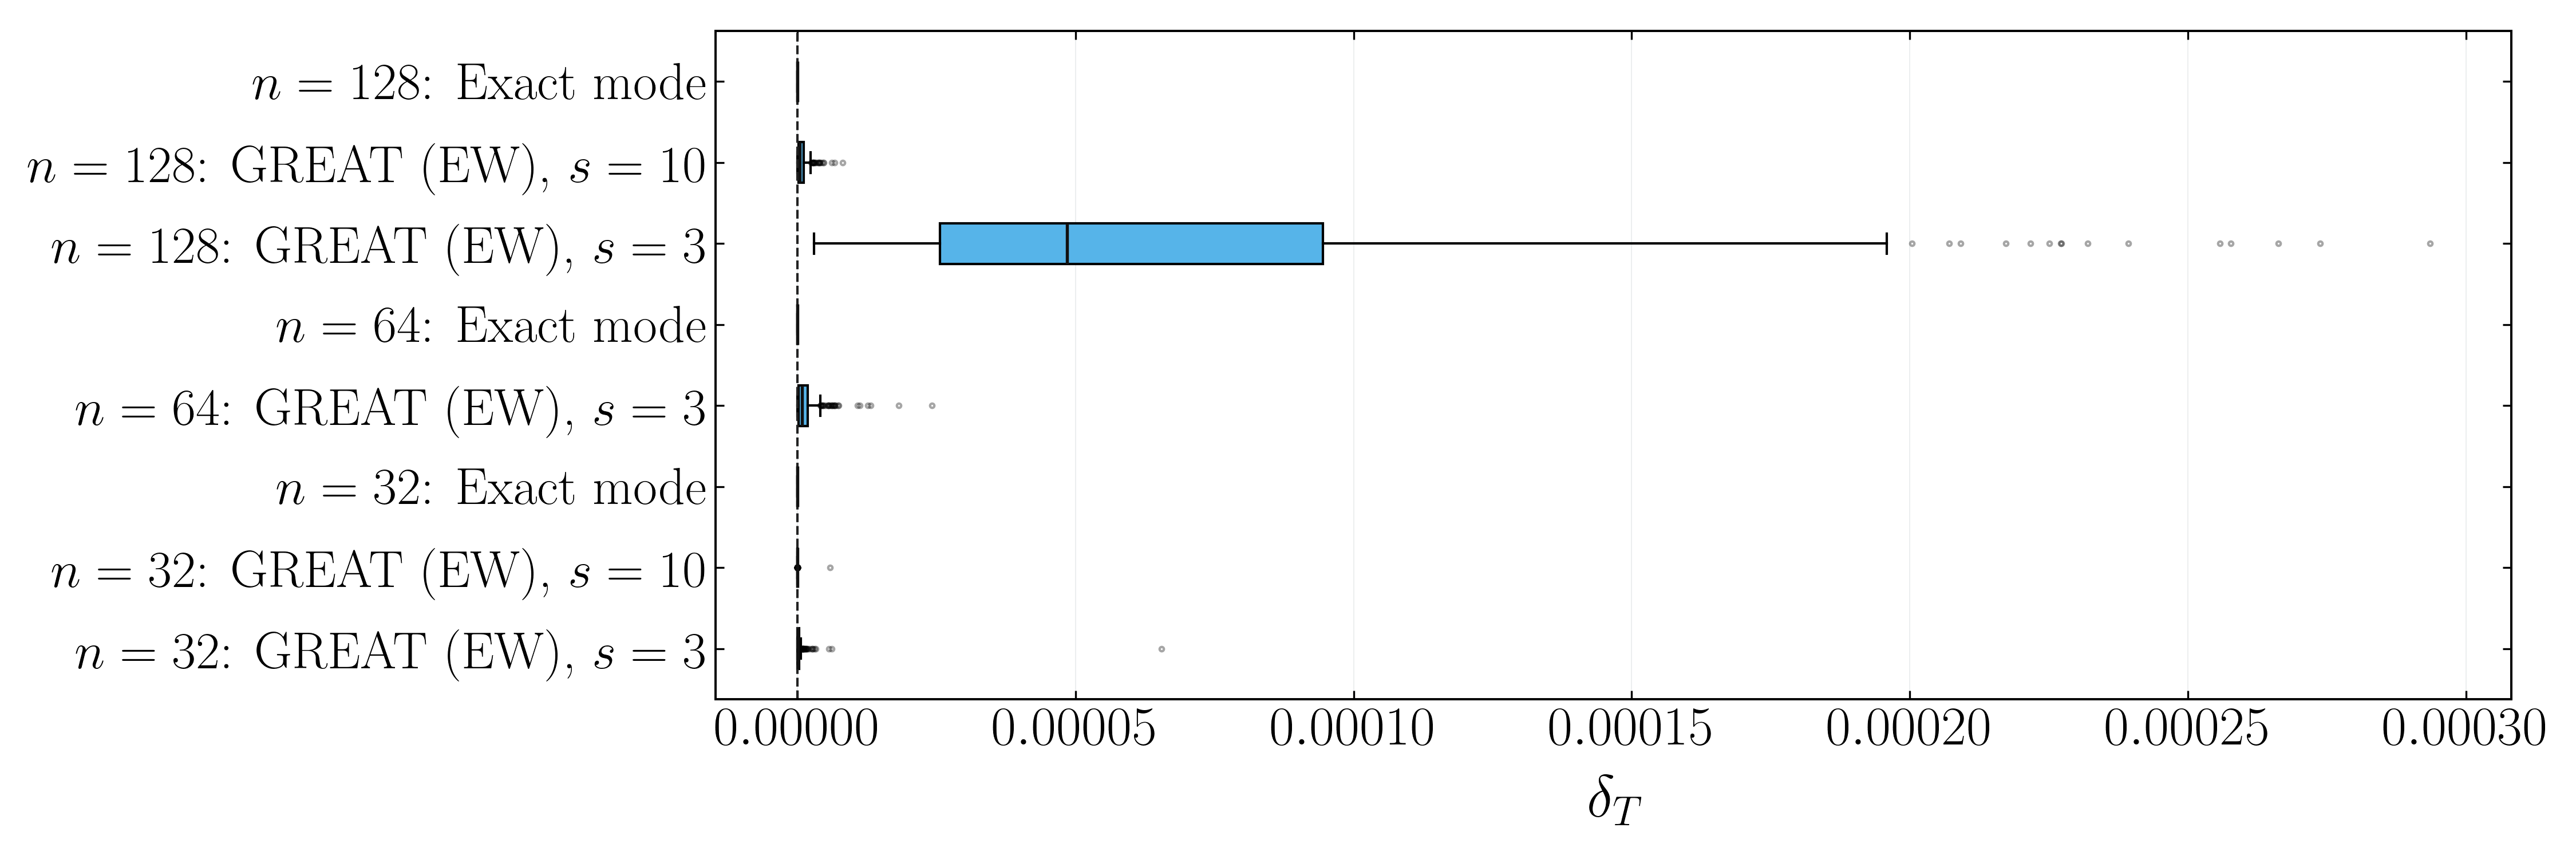

In [9]:
# Edit the canvas, labels, styles and save commands directly in this cell.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'ew_objective_gap.pdf'

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'isotropic': r'$\overline P_t^{\mathrm{iso}}$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
    'covariance_loading': 'Regularized sample covariance',
    'modal_loading':'Regularized mode', 'grouse':'GROUSE',
    'ledoit_wolf':'Ledoit--Wolf', 'oracle':'True covariance',
    'great_window_final_db': r'GREAT, $W=\widehat W_n$',
    'great_full_history_final_db': r'GREAT, $W=T$',
    'great_ew_final_db': 'GREAT (exponential weighting)',
    'covariance_loading_final_db': 'Regularized sample covariance',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'isotropic':'#CC79A7',
    'great_window':'#009E73', 'great_ew':'#56B4E9', 'covariance_loading':'#484848',
    'great_window_final_db':'#009E73', 'great_full_history_final_db':'#006747',
    'great_ew_final_db':'#56B4E9', 'covariance_loading_final_db':'#484848'}
MARKERS = {'mean':'o', 'mode':'s', 'isotropic':'^', 'great_window':'D', 'great_ew':'v',
    'covariance_loading':'X', 'great_window_final_db':'D', 'great_full_history_final_db':'P',
    'great_ew_final_db':'v', 'covariance_loading_final_db':'X'}
LINESTYLES = {'mean':'-', 'mode':'--', 'isotropic':'-.', 'great_window':':',
    'great_ew':(0,(5,1,1,1)), 'covariance_loading':'-',
    'great_window_final_db':':', 'great_full_history_final_db':':',
    'great_ew_final_db':(0,(5,1,1,1)), 'covariance_loading_final_db':'-'}
MARK_OFFSETS = {'mean':0, 'mode':1, 'isotropic':2, 'great_window':0, 'great_ew':2,
    'covariance_loading':1, 'great_window_final_db':0,'great_full_history_final_db':0,
    'great_ew_final_db':2,'covariance_loading_final_db':1}

frame = optimization['test_checkpoints']
if SCOPE == 'stationary':
    frame = frame[frame.t.eq(200)]
# These are per-simulation optimization errors, not posterior credible widths.
values = frame.groupby(['condition','n','method','inner_steps','trial'],sort=True).relative_objective_gap.mean().reset_index()
samples, labels, shades = [], [], []
for (condition,n,method,steps), group in values.groupby(['condition','n','method','inner_steps'],sort=True):
    case = condition.capitalize() if SCOPE == 'moving' else r'$n='+str(int(n))+r'$'
    label = 'Exact mode' if method == 'mode_exact' else r'GREAT (EW), $s='+str(int(steps))+r'$'
    samples.append(group.relative_objective_gap.to_numpy())
    labels.append(case+': '+label)
    shades.append(COLORS['mode'] if method == 'mode_exact' else COLORS['great_ew'])
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
boxes = ax.boxplot(samples, vert=False, patch_artist=True,
    medianprops={'color':'#111111','linewidth':1.3},
    flierprops={'markersize':1.8,'alpha':.35}, manage_ticks=False)
ax.set_yticks(np.arange(1,len(labels)+1), labels=labels)
for box, color in zip(boxes['boxes'], shades):box.set_facecolor(color)
ax.set_xlabel(r'$\overline\delta$' if SCOPE == 'moving' else r'$\delta_T$')
ax.tick_params(axis='y', labelsize=LEGEND_FONT_SIZE)
ax.axvline(0.,color='#222222',linestyle='--',linewidth=1.)
ax.grid(axis='x',color='#BFC4C8',alpha=.30,linewidth=.45)

# Complete rectangular frames; ticks on all sides, labels only left/bottom.
for _axes in fig.axes:
    for _spine in _axes.spines.values():
        _spine.set_visible(True)
        _spine.set_linewidth(.95)
    _axes.tick_params(direction='in', top=True, right=True, labeltop=False, labelright=False)
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
plt.show()


In [10]:
display(Markdown('The following are pooled checkpoint diagnostics over '+
    ('all 32 moving reports' if SCOPE == 'moving' else 'all four stationary reports')+
    '. Their mean and maximum are optimization diagnostics, not the primary task loss.'))
rows = []
for (condition,n,method,steps), group in optimization['test_checkpoints'].groupby(
        ['condition','n','method','inner_steps'],sort=True):
    rows.append({'condition':condition,'n':n,'method':'Exact mode' if method == 'mode_exact' else 'GREAT (EW)',
        'steps':np.nan if method == 'mode_exact' else steps,
        'mean checkpoint gap':group.relative_objective_gap.mean(),
        'maximum relative gap':group.relative_objective_gap.max(),
        'maximum chordal distance to the mode':group.chordal_to_mode.max()})
display(pd.DataFrame(rows))
display(optimization['paired_summary'])


The following are pooled checkpoint diagnostics over all four stationary reports. Their mean and maximum are optimization diagnostics, not the primary task loss.

,condition,n,method,steps,mean checkpoint gap,maximum relative gap,maximum chordal distance to the mode
0,static,32,GREAT (EW),3.0,0.002927,0.270690,0.851779
1,static,32,GREAT (EW),10.0,0.000175,0.008932,0.181625
2,static,32,Exact mode,NaN,0.000000,0.000000,0.000000
3,static,64,GREAT (EW),3.0,0.018933,0.348977,0.992034
4,static,64,Exact mode,NaN,0.000000,0.000000,0.000000
5,static,128,GREAT (EW),3.0,0.052215,0.429301,0.998442
6,static,128,GREAT (EW),10.0,0.007404,0.181015,0.952746
7,static,128,Exact mode,NaN,0.000000,0.000000,0.000000


,condition,n,method,inner_steps,reference,metric,simulations,mean,lower,upper
0,static,32,great_ew,3,mode_exact,final_t200_true_ratio_db_difference,256,-2.209689e-06,-0.000015,1.054533e-05
1,static,32,great_ew,10,mode_exact,final_t200_true_ratio_db_difference,256,-3.719092e-07,-0.000001,4.344006e-07
2,static,64,great_ew,3,mode_exact,final_t200_true_ratio_db_difference,256,9.548075e-06,-0.000028,4.680539e-05
3,static,128,great_ew,3,mode_exact,final_t200_true_ratio_db_difference,256,3.339561e-04,0.000119,5.490375e-04
4,static,128,great_ew,10,mode_exact,final_t200_true_ratio_db_difference,256,1.039187e-05,-0.000013,3.419741e-05


The next display reports paired test-loss differences from the exact common-EW mode and includes the original posterior mean as context. The zero line is the exact-mode reference. Its intervals are pointwise 95% intervals for paired Monte Carlo mean differences. A gap between GREAT EW and that exact mode is an optimization effect. The posterior mean versus exact-mode comparison is the relevant uncertainty/shrinkage comparison under common parameters; neither a finite-step optimization gap nor a separately selected memory can be attributed entirely to anisotropy.

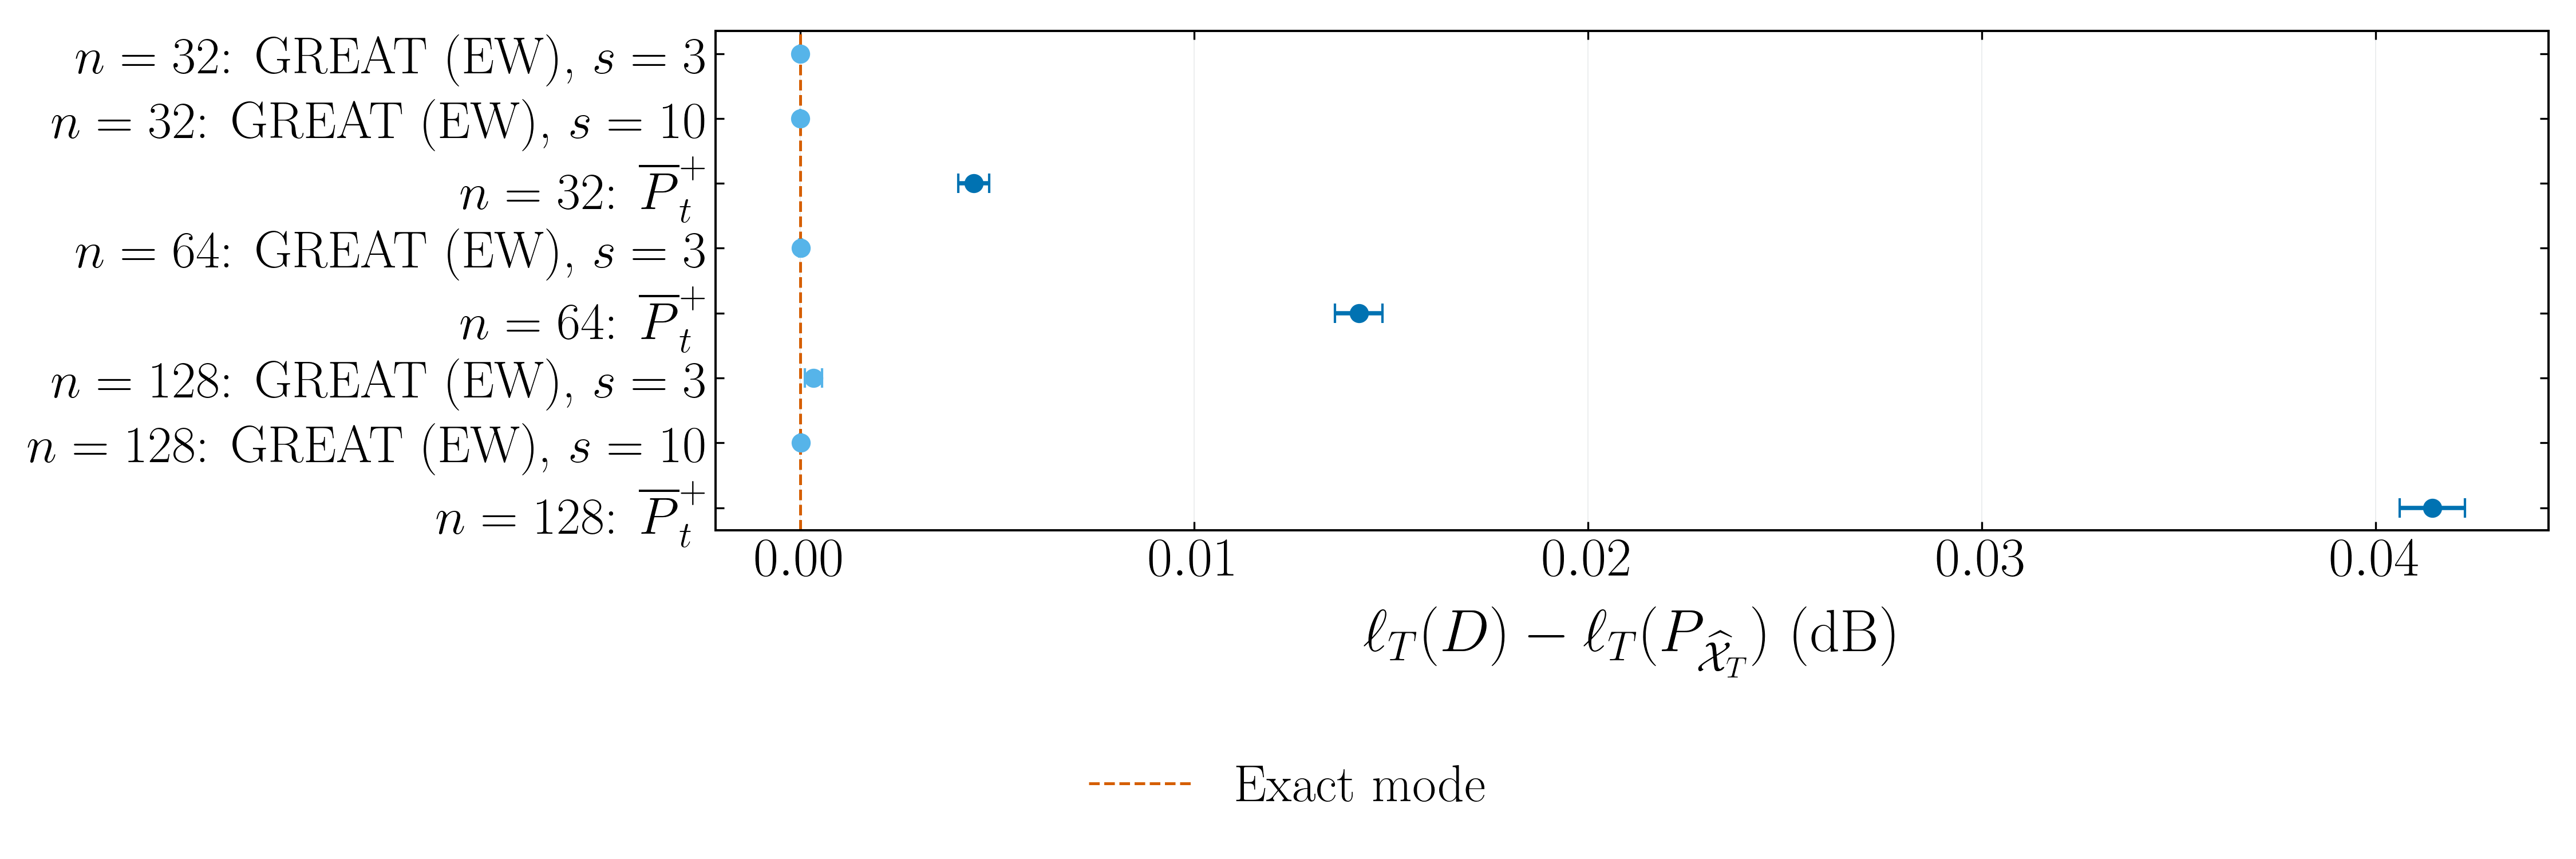

In [11]:
# Edit the canvas, labels, styles and save commands directly in this cell.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'ew_task_power.pdf'

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'isotropic': r'$\overline P_t^{\mathrm{iso}}$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
    'covariance_loading': 'Regularized sample covariance',
    'modal_loading':'Regularized mode', 'grouse':'GROUSE',
    'ledoit_wolf':'Ledoit--Wolf', 'oracle':'True covariance',
    'great_window_final_db': r'GREAT, $W=\widehat W_n$',
    'great_full_history_final_db': r'GREAT, $W=T$',
    'great_ew_final_db': 'GREAT (exponential weighting)',
    'covariance_loading_final_db': 'Regularized sample covariance',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'isotropic':'#CC79A7',
    'great_window':'#009E73', 'great_ew':'#56B4E9', 'covariance_loading':'#484848',
    'great_window_final_db':'#009E73', 'great_full_history_final_db':'#006747',
    'great_ew_final_db':'#56B4E9', 'covariance_loading_final_db':'#484848'}
MARKERS = {'mean':'o', 'mode':'s', 'isotropic':'^', 'great_window':'D', 'great_ew':'v',
    'covariance_loading':'X', 'great_window_final_db':'D', 'great_full_history_final_db':'P',
    'great_ew_final_db':'v', 'covariance_loading_final_db':'X'}
LINESTYLES = {'mean':'-', 'mode':'--', 'isotropic':'-.', 'great_window':':',
    'great_ew':(0,(5,1,1,1)), 'covariance_loading':'-',
    'great_window_final_db':':', 'great_full_history_final_db':':',
    'great_ew_final_db':(0,(5,1,1,1)), 'covariance_loading_final_db':'-'}
MARK_OFFSETS = {'mean':0, 'mode':1, 'isotropic':2, 'great_window':0, 'great_ew':2,
    'covariance_loading':1, 'great_window_final_db':0,'great_full_history_final_db':0,
    'great_ew_final_db':2,'covariance_loading_final_db':1}

frame = optimization['paired_summary']
primary_pairs = existing['paired_primary_summary']
cases = ([('smooth',32),('abrupt',32)] if SCOPE == 'moving' else
         [(str(frame.condition.iloc[0]),n) for n in CONFIG['dimensions']])
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
labels = []
for condition,n in cases:
    case = condition.capitalize() if SCOPE == 'moving' else r'$n='+str(int(n))+r'$'
    for row in frame[frame.condition.eq(condition)&frame.n.eq(n)].sort_values('inner_steps').itertuples():
        label = r'GREAT (EW), $s='+str(int(row.inner_steps))+r'$'
        position = len(labels);labels.append(case+': '+label)
        ax.errorbar(row.mean,position,
            xerr=[[row.mean-row.lower],[row.upper-row.mean]],
            fmt='o',color=COLORS['great_ew'],capsize=4.,markersize=7.)
    # The original mode is the same exact common-EW eigenspace (checked in the audit).
    row = primary_pairs[primary_pairs.reference.eq('mode')]
    row = row[row.condition.eq(condition)] if SCOPE == 'moving' else row[row.n.eq(n)]
    row = row.iloc[0]
    value, lower, upper = -row['mean'], -row['upper'], -row['lower']
    position = len(labels);labels.append(case+': '+LABELS['mean'])
    ax.errorbar(value,position,xerr=[[value-lower],[upper-value]],
                fmt='o',color=COLORS['mean'],capsize=4.,markersize=7.)
ax.axvline(0.,color=COLORS['mode'],linestyle='--',linewidth=1.2,label='Exact mode')
ax.set(yticks=np.arange(len(labels)),yticklabels=labels,
       xlabel=r'$L(D)-L(P_{\widehat{\mathcal X}})$ (dB)' if SCOPE == 'moving'
       else r'$\ell_T(D)-\ell_T(P_{\widehat{\mathcal X}_T})$ (dB)')
ax.tick_params(axis='y',labelsize=LEGEND_FONT_SIZE)
ax.invert_yaxis()
ax.grid(axis='x',color='#BFC4C8',alpha=.30,linewidth=.45)
fig.legend(*ax.get_legend_handles_labels(),loc='outside lower center',frameon=False,fontsize=LEGEND_FONT_SIZE)

# Complete rectangular frames; ticks on all sides, labels only left/bottom.
for _axes in fig.axes:
    for _spine in _axes.spines.values():
        _spine.set_visible(True)
        _spine.set_linewidth(.95)
    _axes.tick_params(direction='in', top=True, right=True, labeltop=False, labelright=False)
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
plt.show()


In [12]:
# Pair every optimizer with the original common-parameter posterior mean.
if SCOPE == 'moving':
    baseline=existing['simulation_aggregates']
    baseline=baseline[baseline.primary & baseline.method.eq('mean')].copy()
    baseline['n']=32
    baseline=baseline[['condition','n','trial','value_db']]
else:
    baseline=existing['raw_stats']
    baseline=baseline[baseline.t.eq(200)&baseline.method.eq('mean')]
    baseline=baseline[['condition','n','trial','true_ratio_db']].rename(columns={'true_ratio_db':'value_db'})
frame=optimization['test_checkpoints']
if SCOPE == 'stationary':frame=frame[frame.t.eq(200)]
scores=frame.groupby(['condition','n','method','inner_steps','trial'],sort=True).true_ratio_db.mean().reset_index()
paired=scores.merge(baseline,on=['condition','n','trial'],validate='many_to_one')
paired['difference_db']=paired.true_ratio_db-paired.value_db
rows=[]
for (condition,n,method,steps), group in paired.groupby(['condition','n','method','inner_steps'],sort=True):
    assert len(group)==256 and group.trial.nunique()==256
    values=group.difference_db.to_numpy()
    mean=values.mean()
    half=student_t.ppf(.975,255)*values.std(ddof=1)/16.
    rows.append({'condition':condition,'n':n,
        'Reference':'Exact mode' if method=='mode_exact' else 'GREAT (EW)',
        'Gradient steps':np.nan if method=='mode_exact' else int(steps),
        'Reference minus posterior mean (dB)':mean,'95% lower':mean-half,'95% upper':mean+half,
        'simulations':256})
optimizer_pairs=pd.DataFrame(rows)
display(optimizer_pairs)
EDITABLE_OUTPUT.mkdir(parents=True,exist_ok=True)
optimizer_pairs.to_csv(EDITABLE_OUTPUT/'optimizer_paired_vs_mean.csv',index=False)
display(Markdown('These differences use the same original simulation in each pair. Positive '
    'values favor the posterior mean; negative values favor the reference. The selected finite-step '
    'GREAT result is not assumed to be fully converged.'))


,condition,n,Reference,Gradient steps,Reference minus posterior mean (dB),95% lower,95% upper,simulations
0,static,32,GREAT (EW),3.0,-0.004404,-0.004794,-0.004013,256
1,static,32,GREAT (EW),10.0,-0.004402,-0.004793,-0.004011,256
2,static,32,Exact mode,NaN,-0.004402,-0.004792,-0.004011,256
3,static,64,GREAT (EW),3.0,-0.014174,-0.014786,-0.013563,256
4,static,64,Exact mode,NaN,-0.014184,-0.014790,-0.013578,256
5,static,128,GREAT (EW),3.0,-0.041116,-0.041982,-0.040250,256
6,static,128,GREAT (EW),10.0,-0.041440,-0.042272,-0.040607,256
7,static,128,Exact mode,NaN,-0.041450,-0.042281,-0.040619,256


These differences use the same original simulation in each pair. Positive values favor the posterior mean; negative values favor the reference. The selected finite-step GREAT result is not assumed to be fully converged.

## Cost of the finite-step comparison

The timings were collected in a separate isolated, warmed single-thread run. Each moving workload processes 256 measurements and 32 task decisions; each stationary workload processes 200 measurements and its four original task reports. All GREAT updates are included. The exact-mode workload updates the same covariance and computes its eigenspace only when a task decision is reported. Diagnostic eigendecompositions used to measure optimization error are excluded from GREAT timings.

These clocks compare GREAT EW with the exact mode; they do not time the posterior mean. Repeated clock measurements describe execution variability, not independent Monte Carlo task simulations or a worst-case deadline. The boxes show medians and interquartile ranges, with 1.5-IQR whiskers and all outliers.

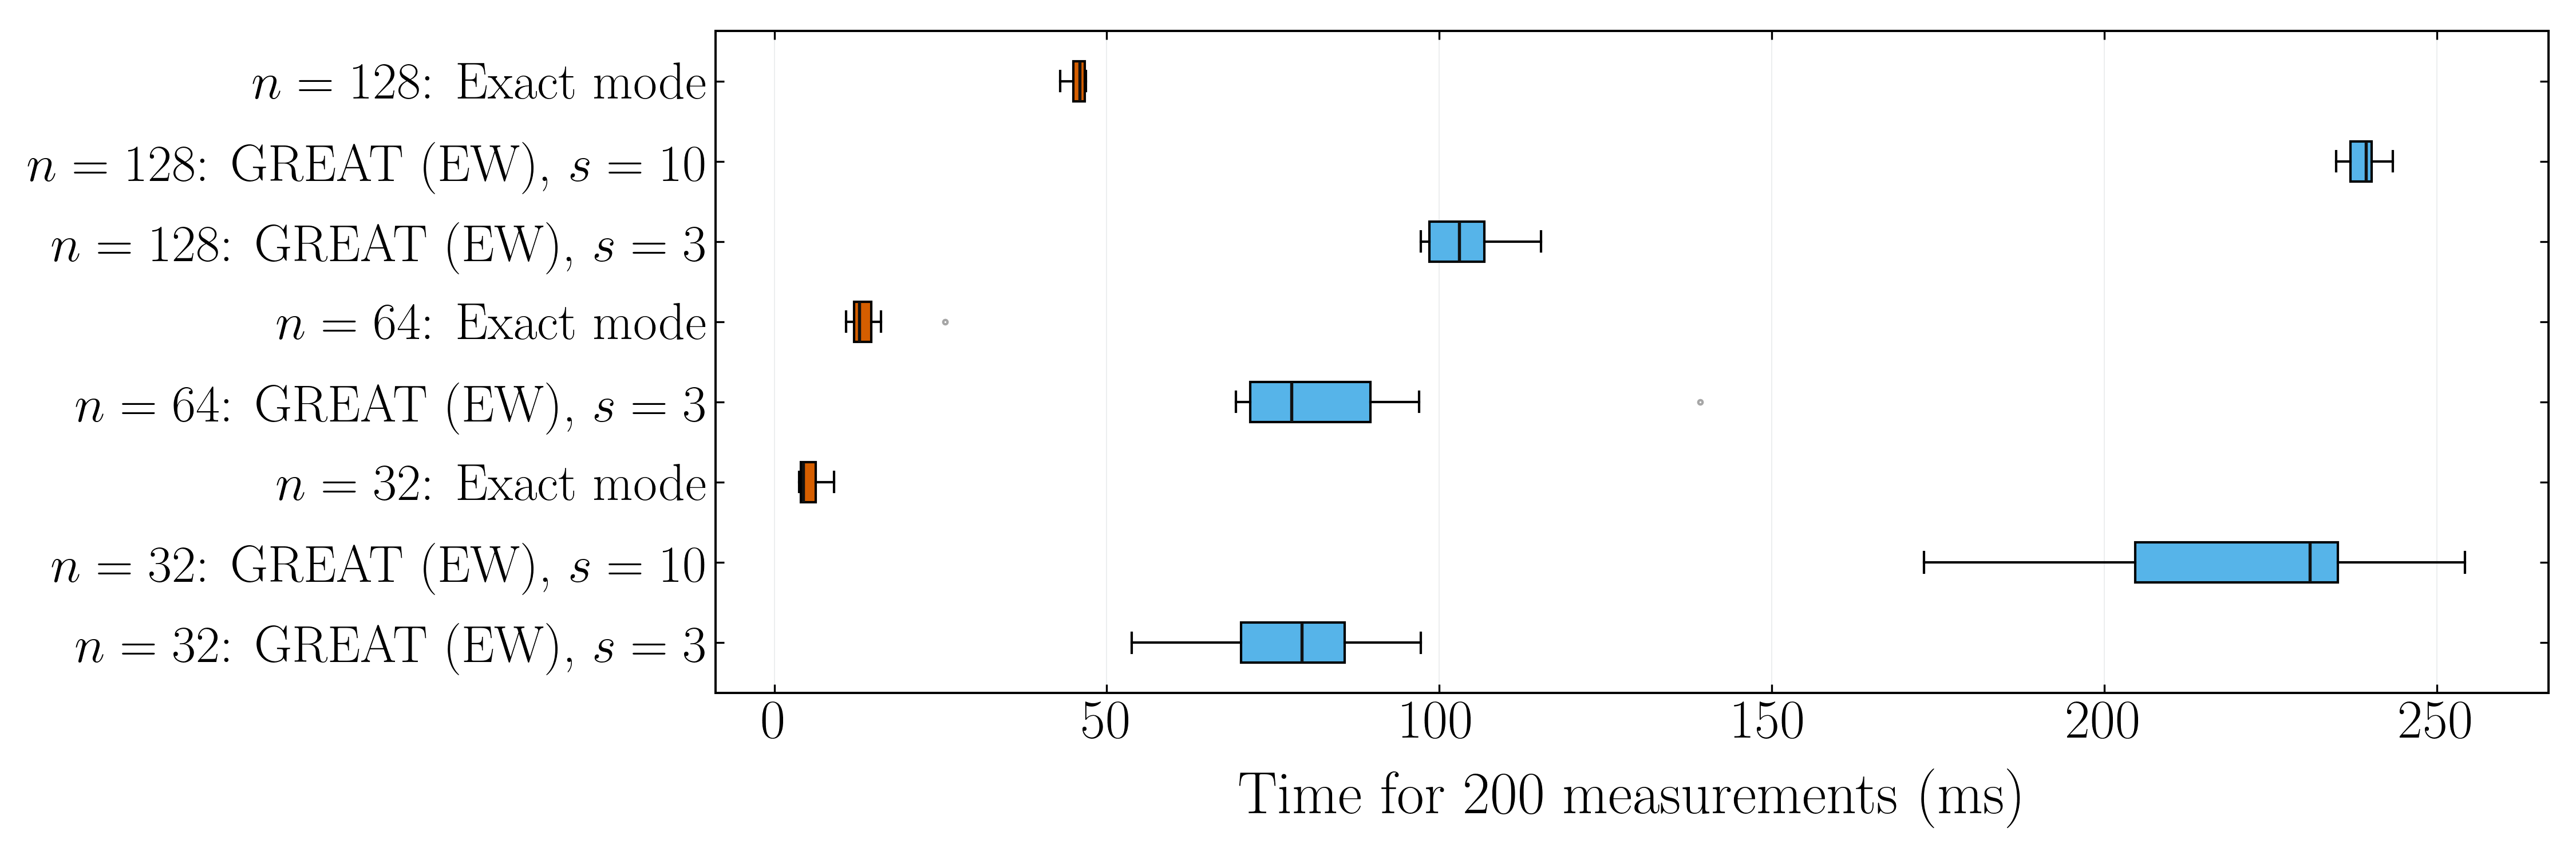

In [13]:
# Edit the canvas, labels, styles and save commands directly in this cell.
DPI = 300
FIGSIZE = (15, 5)
LABEL_FONT_SIZE = 25.
TICK_FONT_SIZE = 23.
LEGEND_FONT_SIZE = 22.
plt.rcParams.update({
    'text.usetex': True, 'font.family': 'serif', 'font.size': LABEL_FONT_SIZE,
    'axes.labelsize': LABEL_FONT_SIZE, 'axes.titlesize': LABEL_FONT_SIZE,
    'xtick.labelsize': TICK_FONT_SIZE, 'ytick.labelsize': TICK_FONT_SIZE,
    'legend.fontsize': LEGEND_FONT_SIZE, 'axes.labelpad': 8.,
    'figure.dpi': DPI, 'savefig.dpi': DPI,
})
SAVE_PDF = True
PDF_PATH = EDITABLE_OUTPUT / 'computation_time.pdf'

LABELS = {
    'mean': r'$\overline P_t^+$', 'mode': r'$P_{\widehat{\mathcal X}_t}$',
    'isotropic': r'$\overline P_t^{\mathrm{iso}}$',
    'great_window': 'GREAT (sliding window)', 'great_ew': 'GREAT (exponential weighting)',
    'covariance_loading': 'Regularized sample covariance',
    'modal_loading':'Regularized mode', 'grouse':'GROUSE',
    'ledoit_wolf':'Ledoit--Wolf', 'oracle':'True covariance',
    'great_window_final_db': r'GREAT, $W=\widehat W_n$',
    'great_full_history_final_db': r'GREAT, $W=T$',
    'great_ew_final_db': 'GREAT (exponential weighting)',
    'covariance_loading_final_db': 'Regularized sample covariance',
}
COLORS = {'mean':'#0072B2', 'mode':'#D55E00', 'isotropic':'#CC79A7',
    'great_window':'#009E73', 'great_ew':'#56B4E9', 'covariance_loading':'#484848',
    'great_window_final_db':'#009E73', 'great_full_history_final_db':'#006747',
    'great_ew_final_db':'#56B4E9', 'covariance_loading_final_db':'#484848'}
MARKERS = {'mean':'o', 'mode':'s', 'isotropic':'^', 'great_window':'D', 'great_ew':'v',
    'covariance_loading':'X', 'great_window_final_db':'D', 'great_full_history_final_db':'P',
    'great_ew_final_db':'v', 'covariance_loading_final_db':'X'}
LINESTYLES = {'mean':'-', 'mode':'--', 'isotropic':'-.', 'great_window':':',
    'great_ew':(0,(5,1,1,1)), 'covariance_loading':'-',
    'great_window_final_db':':', 'great_full_history_final_db':':',
    'great_ew_final_db':(0,(5,1,1,1)), 'covariance_loading_final_db':'-'}
MARK_OFFSETS = {'mean':0, 'mode':1, 'isotropic':2, 'great_window':0, 'great_ew':2,
    'covariance_loading':1, 'great_window_final_db':0,'great_full_history_final_db':0,
    'great_ew_final_db':2,'covariance_loading_final_db':1}

clock = optimization['timing']['raw']
samples, labels, shades = [], [], []
for (condition,n,method,steps), group in clock.groupby(['condition','n','method','inner_steps'],sort=True):
    case = condition.capitalize() if SCOPE == 'moving' else r'$n='+str(int(n))+r'$'
    label = 'Exact mode' if method == 'mode_exact' else r'GREAT (EW), $s='+str(int(steps))+r'$'
    samples.append(group.total_ms.to_numpy())
    labels.append(case+': '+label)
    shades.append(COLORS['mode'] if method == 'mode_exact' else COLORS['great_ew'])
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI, layout='constrained')
boxes = ax.boxplot(samples,vert=False,patch_artist=True,
    medianprops={'color':'#111111','linewidth':1.3},flierprops={'markersize':1.8,'alpha':.35},manage_ticks=False)
ax.set_yticks(np.arange(1,len(labels)+1),labels=labels)
for box,color in zip(boxes['boxes'],shades):box.set_facecolor(color)
ax.set_xlabel('Time for '+str(CONFIG['T'])+' measurements (ms)')
ax.tick_params(axis='y',labelsize=LEGEND_FONT_SIZE)
ax.grid(axis='x',color='#BFC4C8',alpha=.30,linewidth=.45)

# Complete rectangular frames; ticks on all sides, labels only left/bottom.
for _axes in fig.axes:
    for _spine in _axes.spines.values():
        _spine.set_visible(True)
        _spine.set_linewidth(.95)
    _axes.tick_params(direction='in', top=True, right=True, labeltop=False, labelright=False)
fig.get_layout_engine().set(h_pad=.18, w_pad=.16)
if SAVE_PDF:
    PDF_PATH.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(PDF_PATH, dpi=DPI, bbox_inches=None)
    PNG_PATH = PDF_PATH.with_suffix('.png')
    fig.savefig(PNG_PATH, dpi=DPI, bbox_inches=None)
plt.show()


In [14]:
clock_summary=optimization['timing']['summary'].copy()
operations=optimization['operation_counts'].copy()
for table in [clock_summary,operations]:
    table.loc[table.method.eq('mode_exact'),'inner_steps']=np.nan
    table['method']=table.method.replace({'mode_exact':'Exact mode','great_ew':'GREAT (EW)'})
display(clock_summary)
display(operations)

,condition,n,T,method,inner_steps,repetitions,median_ms,p90_ms
0,static,32,200,GREAT (EW),3.0,7,79.359143,92.197153
1,static,32,200,GREAT (EW),10.0,7,230.894952,244.924555
2,static,32,200,Exact mode,NaN,7,4.324964,7.536115
3,static,64,200,GREAT (EW),3.0,7,77.787782,113.843120
4,static,64,200,Exact mode,NaN,7,12.765415,19.904882
5,static,128,200,GREAT (EW),3.0,7,102.998661,111.655695
6,static,128,200,GREAT (EW),10.0,7,239.373720,241.746053
7,static,128,200,Exact mode,NaN,7,45.925791,46.857009


,condition,n,method,inner_steps,measurements,covariance_updates,grassmann_steps,task_decisions,diagnostic_eigendecompositions,tracker_eigendecompositions,scope
0,static,32,GREAT (EW),3.0,200,200,600,4,4,0,Diagnostic eigenspaces excluded from future ti...
1,static,32,GREAT (EW),10.0,200,200,2000,4,4,0,Diagnostic eigenspaces excluded from future ti...
2,static,32,Exact mode,NaN,200,200,0,4,0,4,Exact mode at the common task reporting times
3,static,64,GREAT (EW),3.0,200,200,600,4,4,0,Diagnostic eigenspaces excluded from future ti...
4,static,64,Exact mode,NaN,200,200,0,4,0,4,Exact mode at the common task reporting times
5,static,128,GREAT (EW),3.0,200,200,600,4,4,0,Diagnostic eigenspaces excluded from future ti...
6,static,128,GREAT (EW),10.0,200,200,2000,4,4,0,Diagnostic eigenspaces excluded from future ti...
7,static,128,Exact mode,NaN,200,200,0,4,0,4,Exact mode at the common task reporting times


## Reading the comparisons

The posterior-mean MVDR decision minimizes posterior expected linear output power. That statement does not imply optimality for an average individual-dB loss, or for every fixed generating parameter or moving trajectory. The same-parameter mean/mode/isotropic results, finite-step optimization results and independently selected parameter results answer different questions. Positive and negative paired differences are retained throughout.

The original GREAT EW implementation performs a finite optimization update. Its distance from the exact common-EW mode must be checked before using a mean-versus-GREAT difference as evidence for posterior uncertainty. Sliding-window GREAT can also use a different observation history. The independent validation audits separate those effects while preserving the original comparisons.

The primary outcome was defined before examining the rankings. Secondary averaging conventions remain visible because they can reverse a small comparison. All pointwise intervals and raw paired simulation differences are saved alongside this notebook's figures; none of these displays establishes universal superiority or posterior coverage under an unmodelled transition.

## Saved audit records

[Figures](../results/beamforming_comparison_audit/stationary/figures/) · [Original-setting summaries](../results/beamforming_comparison_audit/stationary/existing/) · [Mean-memory validation](../results/beamforming_comparison_audit/stationary/mean_validation/) · [EW objective and isolated timings](../results/beamforming_comparison_audit/stationary/objective/) · [Final-measurement selection](../results/beamforming_comparison_audit/stationary/selection/)